# Avance 5. Modelo final
## Sistema de conteo de productos Vetlife — Equipo 32

**Fecha:** 31 de octubre de 2026
**Datos:** 44 fotografías de anaquel anotadas en Label Studio, 676 productos individuales, 44 clases
**Objetivo:** construir **modelos de ensamble** (homogéneos y heterogéneos) que **mejoren al mejor modelo individual del Avance 4**, compararlos con un mismo protocolo, **elegir el modelo final** según las necesidades del negocio y **evaluarlo con gráficos interpretados** sobre fotografías que ningún modelo vio.

> **Punto de partida (Avance 4).** El mejor modelo individual fue una regresión logística (C ≈ 16, pesos de clase balanceados, PCA a 256 componentes) sobre las variables E: 92 características de color, forma y textura más 768 valores de una ConvNeXt-Tiny preentrenada y congelada. Obtuvo un macro-F1 de 0.544 ± 0.128 en validación cruzada y de 0.253 en una prueba de 10 fotos; el LDA ajustado quedó cerca (0.518 y 0.270). Los errores se concentraban entre presentaciones casi idénticas de una misma línea (dosis, número de tabletas). Este avance pregunta **si combinar modelos cierra esa brecha** y a qué costo en tiempo, tamaño e interpretabilidad.

## 1. Qué pide el avance y dónde se responde

| Requisito | Dónde se responde |
|---|---|
| ≥ 4 modelos de ensamble, con estrategias **homogéneas** y **heterogéneas** | §5 (homogéneos): bosque aleatorio, árboles extremadamente aleatorios, *bagging* de regresión logística y *gradient boosting*. §6 (heterogéneos): votación suave, apilamiento (*stacking*) y mezcla (*blending*). En total **7 ensambles** |
| Optimización de hiperparámetros de los modelos relevantes | §5 y §6: búsqueda aleatoria (RF, ET, *bagging*, *boosting*) y rejilla (votación, mezcla); el apilamiento elige el C de su metamodelo con predicciones fuera de muestra |
| *Stacking* / *blending* con los **mejores individuales** de la fase previa | §6: base = regresión logística y LDA ajustados + SVM lineal + MLP, todos sobre las variables E del Avance 4 |
| Tabla comparativa con los individuales previos, ordenada por la métrica principal, con otras métricas y **tiempos de entrenamiento** | §7 |
| Elección del modelo final alineada con el negocio | §8 |
| Gráficos del modelo final con interpretación (curva ROC, matriz de confusión, precisión-recall, importancia de características, residuos…) | §9: **seis gráficos** interpretados |
| Declaración de uso de IA | Última sección |

**Protocolo (idéntico al Avance 4, para que todo sea comparable).** Partición por fotografía (34 fotos de entrenamiento, 10 de prueba, semilla 42); validación cruzada de 5 pliegues **agrupada por foto** solo con entrenamiento para elegir hiperparámetros y modelos; la prueba se evalúa **una sola vez** por modelo y nunca se usa para decidir. Métrica principal: **macro-F1 sobre las clases presentes en la verdad de terreno**. Complementarias: *balanced accuracy*, top-3, exactitud por línea y, en prueba, error de conteo.

## 2. Dependencias y datos

Se usa Python, NumPy, pandas, Pillow, scikit-image, scikit-learn, PyTorch/torchvision (solo para extraer *embeddings*), Matplotlib y seaborn. La libreta busca localmente las fotografías (`label_data/`) y las exportaciones de Label Studio; **no se distribuyen en el repositorio**. Se debe ejecutar completa y en orden: las secciones posteriores dependen de las variables de las anteriores.

In [ ]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"      # los procesos paralelos de scikit-learn heredan el filtro y no ensucian las salidas
from pathlib import Path
import json, urllib.parse, time, platform, warnings, io, pickle
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw, ImageOps
from IPython.display import display
from scipy.ndimage import laplace
from scipy.stats import loguniform, uniform, randint
from skimage.color import rgb2hsv
from skimage.feature import hog
from skimage.filters import sobel
from skimage.measure import shannon_entropy

import sklearn, torch, torchvision, joblib
from torchvision import transforms as T
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier,
                              HistGradientBoostingClassifier, VotingClassifier)
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import (f1_score, balanced_accuracy_score, make_scorer, confusion_matrix,
                             roc_curve, auc, precision_recall_curve, average_precision_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 170)
SEED = 42
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | torch {torch.__version__}")

Python 3.9.6 | numpy 2.0.2 | pandas 2.3.3 | scikit-learn 1.6.1 | torch 2.8.0


In [ ]:
# Búsqueda de datos: funciona al ejecutar desde la raíz del proyecto, desde avances/ o desde Zproyect_Main/.
BASES = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
def find_dir(options):
    for base in BASES:
        for rel in options:
            if (base / rel).is_dir():
                return (base / rel).resolve()
    return None

PHOTO_DIR  = find_dir(["label_data", "Vetlife_Proyecto/label_data"])
EXPORT_DIR = find_dir(["Zproyect_Main/01_datos/exportaciones_label_studio", "01_datos/exportaciones_label_studio",
                       "Vetlife_Proyecto/Zproyect_Main/01_datos/exportaciones_label_studio"])
REF_DIR    = find_dir(["Zproyect_Main/Fotos_de_referencia", "Fotos_de_referencia", "Vetlife_Proyecto/Zproyect_Main/Fotos_de_referencia"])
if PHOTO_DIR is None or EXPORT_DIR is None:
    raise FileNotFoundError("Colocar label_data/ y las exportaciones de Label Studio junto al proyecto (ver README).")
print("Fotos anotadas  :", PHOTO_DIR.name, "| Exportaciones:", [p.name for p in sorted(EXPORT_DIR.iterdir()) if p.is_dir()])
print("Fotos de referencia:", REF_DIR.name if REF_DIR else "no disponibles")

Fotos anotadas  : label_data | Exportaciones: ['2026-10-15', '2026-10-17']
Fotos de referencia: Fotos_de_referencia


### 2.1 Anotaciones y características por producto

Se reutiliza el procesamiento de los Avances 3 y 4: se leen las exportaciones de Label Studio, se agrupan los polígonos por fotografía, se descartan duplicados y cada polígono se recorta de la foto. Cada fila es **un producto con su etiqueta real** descrito por 92 características de geometría, color, matiz, distribución de color 3×3, textura y HOG.

In [ ]:
def box_iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

def load_annotations(export_dir, photo_dir):
    index = {}
    for p in photo_dir.rglob("*"):
        if p.is_file(): index.setdefault(p.name.casefold(), []).append(p)
    photos, unresolved, ignored = {}, 0, 0
    for export in sorted(export_dir.rglob("*.json")):
        tasks = json.loads(export.read_text(encoding="utf-8-sig"))
        tasks = tasks.get("tasks", [tasks]) if isinstance(tasks, dict) else tasks
        for task in tasks:
            ref = str((task.get("data") or {}).get("image", "")).replace("\\", "/").replace("%5C", "/")
            rel = urllib.parse.parse_qs(urllib.parse.urlparse(ref).query).get("d", [urllib.parse.urlparse(ref).path])[0]
            matches = index.get(Path(urllib.parse.unquote(rel)).name.casefold(), [])
            if len(matches) != 1:
                unresolved += 1; continue
            entry = photos.setdefault(matches[0], {"polys": [], "seen": set()})
            for ann in task.get("annotations", []):
                if ann.get("was_cancelled"): continue
                for res in ann.get("result", []):
                    val = res.get("value") or {}
                    if res.get("type") != "polygonlabels" or not val.get("polygonlabels") or len(val.get("points", [])) < 3:
                        ignored += 1; continue
                    pts = [(float(x), float(y)) for x, y in val["points"]]
                    key = (val["polygonlabels"][0], tuple((round(x, 3), round(y, 3)) for x, y in pts))
                    if key in entry["seen"]: continue
                    entry["seen"].add(key)
                    entry["polys"].append((val["polygonlabels"][0].strip(), pts, int(res.get("image_rotation") or 0)))
    return photos, unresolved, ignored

photos, unresolved, ignored = load_annotations(EXPORT_DIR, PHOTO_DIR)
print(f"Fotos con anotaciones: {len(photos)} | tareas sin foto: {unresolved} | resultados ignorados (no polígonos): {ignored}")

Fotos con anotaciones: 44 | tareas sin foto: 0 | resultados ignorados (no polígonos): 1


In [ ]:
FEATURE_GROUPS = {"geo_": "Geometría", "col_": "Color global", "hue_": "Matiz", "lay_": "Distribución de color 3×3",
                  "tex_": "Textura", "hog_": "Formas (HOG)"}

def crop_features(img, pts_pct, W, H):
    poly = [(x * W / 100, y * H / 100) for x, y in pts_pct]
    xs, ys = zip(*poly)
    x1, y1, x2, y2 = max(0, int(min(xs))), max(0, int(min(ys))), min(W, int(np.ceil(max(xs)))), min(H, int(np.ceil(max(ys))))
    bw, bh = x2 - x1, y2 - y1
    if bw < 8 or bh < 8:
        return None, None
    crop = img.crop((x1, y1, x2, y2))
    m = Image.new("L", (bw, bh), 0); ImageDraw.Draw(m).polygon([(x - x1, y - y1) for x, y in poly], fill=1)
    mask = np.asarray(m, bool)
    if mask.sum() < 30:
        return None, None
    a = np.asarray(crop, np.float32) / 255; hsv = rgb2hsv(a)
    area = 0.5 * abs(sum(poly[i][0] * poly[(i + 1) % len(poly)][1] - poly[(i + 1) % len(poly)][0] * poly[i][1] for i in range(len(poly))))
    f = {"geo_ancho_rel": bw / W, "geo_alto_rel": bh / H, "geo_aspecto": bw / bh, "geo_area_rel": bw * bh / (W * H),
         "geo_cx": (x1 + x2) / 2 / W, "geo_cy": (y1 + y2) / 2 / H, "geo_relleno": min(1, area / (bw * bh))}
    px, hp = a[mask], hsv[mask]
    for i, c in enumerate("rgb"):
        f[f"col_{c}_media"] = px[:, i].mean(); f[f"col_{c}_std"] = px[:, i].std()
    f.update({"col_sat_media": hp[:, 1].mean(), "col_sat_std": hp[:, 1].std(), "col_val_media": hp[:, 2].mean(), "col_val_std": hp[:, 2].std()})
    hh, _ = np.histogram(hp[:, 0], bins=12, range=(0, 1), weights=hp[:, 1] + 1e-6); hh = hh / hh.sum()
    for i, v in enumerate(hh): f[f"hue_{i:02d}"] = v
    filled = np.where(mask[..., None], a, px.mean(0))
    small = np.asarray(Image.fromarray((filled * 255).astype(np.uint8)).resize((48, 48), Image.Resampling.BILINEAR), np.float32) / 255
    for r in range(3):
        for c in range(3):
            blk = small[r * 16:(r + 1) * 16, c * 16:(c + 1) * 16].mean((0, 1))
            for k, n in enumerate("rgb"): f[f"lay_{r}{c}_{n}"] = blk[k]
    g = small.mean(2); e = sobel(g)
    f.update({"tex_borde_media": e.mean(), "tex_borde_densidad": (e > 0.1).mean(), "tex_laplaciano_var": laplace(g).var(), "tex_entropia": shannon_entropy(g)})
    for i, v in enumerate(hog(g, orientations=8, pixels_per_cell=(24, 24), cells_per_block=(1, 1), feature_vector=True)):
        f[f"hog_{i:02d}"] = v
    thumb = crop.copy(); thumb.thumbnail((120, 120))
    return f, thumb

def linea(c):
    for prefix, name in [("Bravecto 1M Triple", "Bravecto 1M Triple"), ("Bravecto 1M", "Bravecto 1M"), ("Bravecto Spot", "Bravecto Spot On"),
                         ("Bravecto Plus", "Bravecto Plus gato"), ("Bravecto 365", "Bravecto 365"), ("Bravecto", "Bravecto por peso"),
                         ("Nobivac", "Nobivac"), ("Numelvi", "Numelvi"), ("Quantum", "Quantum Dog")]:
        if c.startswith(prefix): return name
    return "Otro"
marca = lambda c: c.split()[0].replace("NobivacFeline", "Nobivac")

def embedding_crop(img, pts_pct, W, H, margin=0.10, max_side=448):
    """Recorte rectangular con 10 % de margen, en su proporción original (sin relleno), para la CNN."""
    xs, ys = [x * W / 100 for x, _ in pts_pct], [y * H / 100 for _, y in pts_pct]
    bw, bh = max(xs) - min(xs), max(ys) - min(ys)
    box = (max(0, int(min(xs) - margin * bw)), max(0, int(min(ys) - margin * bh)), min(W, int(max(xs) + margin * bw)), min(H, int(max(ys) + margin * bh)))
    crop = img.crop(box); crop.thumbnail((max_side, max_side))
    return crop

t0 = time.time()
rows, THUMBS, POLYS, EMB_CROPS, FEAT_T = [], [], [], [], []
PHOTO_PATH = {}
for path, entry in sorted(photos.items(), key=lambda kv: str(kv[0]).casefold()):
    with Image.open(path) as src:
        img = ImageOps.exif_transpose(src).convert("RGB")
    img.thumbnail((1600, 1600)); W, H = img.size
    PHOTO_PATH[path.name] = path
    kept = []
    for label, pts, rotation in entry["polys"]:
        if rotation != 0: continue
        xs, ys = [p[0] for p in pts], [p[1] for p in pts]; box = [min(xs), min(ys), max(xs), max(ys)]
        if any(l == label and box_iou(b, box) > 0.9 for l, b in kept): continue
        _t = time.perf_counter(); f, thumb = crop_features(img, pts, W, H); FEAT_T.append(time.perf_counter() - _t)
        if f is None: continue
        kept.append((label, box))
        rows.append({"foto": path.name, "clase": label, "linea": linea(label), "marca": marca(label), **f}); THUMBS.append(thumb); POLYS.append(pts); EMB_CROPS.append(embedding_crop(img, pts, W, H))
df = pd.DataFrame(rows)
FEATURES = [c for c in df.columns if c.startswith(tuple(FEATURE_GROUPS))]
GROUP_OF = {c: next(v for k, v in FEATURE_GROUPS.items() if c.startswith(k)) for c in FEATURES}
print(f"Productos (filas): {len(df)} | fotos: {df.foto.nunique()} | clases: {df.clase.nunique()} | características: {len(FEATURES)} | {time.time() - t0:.0f} s")
print("Valores faltantes:", int(df[FEATURES].isna().sum().sum()), "| infinitos:", int(np.isinf(df[FEATURES].values).sum()))
display(pd.Series(Counter(GROUP_OF.values())).rename("n_características").to_frame())

Productos (filas): 676 | fotos: 44 | clases: 44 | características: 92 | 13 s
Valores faltantes: 0 | infinitos: 0


,n_características
Geometría,7
Color global,10
Matiz,12
Distribución de color 3×3,27
Textura,4
Formas (HOG),32


## 3. Partición y representación

### 3.1 Partición entrenamiento / prueba

Es **exactamente la misma partición de los Avances 3 y 4** (por fotografía, estratificada por clase, semilla 42): los productos de una misma foto comparten luz, ángulo y fondo, y separarlos entre entrenamiento y prueba haría la prueba artificialmente fácil. Todo el ajuste usa solo el entrenamiento; las 10 fotos de prueba se tocan una vez por modelo.

In [ ]:
X_A = df[FEATURES].values; y = df.clase.values; groups = df.foto.values
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(X_A, y, groups))
ytr, gtr, yte, gte = y[train_idx], groups[train_idx], y[test_idx], groups[test_idx]
assert not set(gtr) & set(gte), "una foto no puede estar en ambos conjuntos"

unseen = sorted(set(yte) - set(ytr))
print(f"Entrenamiento: {len(train_idx)} productos / {len(set(gtr))} fotos / {len(set(ytr))} clases")
print(f"Prueba       : {len(test_idx)} productos / {len(set(gte))} fotos / {len(set(yte))} clases")
print(f"Clases de prueba ausentes en entrenamiento: {len(unseen)} ({int(np.isin(yte, unseen).sum())} productos que ningún modelo puede acertar)")
prev = EXPORT_DIR.parent / "avance3_fotos_prueba.csv"
if prev.exists():
    print("¿La partición coincide con la del Avance 3?", set(pd.read_csv(prev).foto_prueba) == set(gte))

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)   # validación cruzada interna: solo entrenamiento, agrupada por foto

Entrenamiento: 515 productos / 34 fotos / 41 clases
Prueba       : 161 productos / 10 fotos / 27 clases
Clases de prueba ausentes en entrenamiento: 3 (14 productos que ningún modelo puede acertar)
¿La partición coincide con la del Avance 3? True


### 3.2 Representación E (la del modelo final del Avance 4)

Cada recorte se pasa por **ConvNeXt-Tiny** preentrenada en ImageNet y congelada (el extractor más informativo de los cuatro que se compararon en el Avance 4, §4.1) y se toma el vector previo a la capa de clasificación (768 valores). La representación **E** concatena las 92 características a mano con ese *embedding* (860 variables). No se vuelven a comparar extractores ni tamaños de entrada: eso ya se resolvió en el Avance 4 y aquí el objetivo es el **modelado**. Los recortes conservan su proporción original (lado mayor de 320 px).

In [ ]:
torch.manual_seed(SEED)
to_tensor = T.Compose([T.ToTensor(), T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])

def native_resize(c, long_side=320, min_side=48):
    s = long_side / max(c.size)
    return c.resize((max(min_side, round(c.width * s)), max(min_side, round(c.height * s))), Image.Resampling.BILINEAR)

def extract_embeddings(long_side=320, warmup=8):
    """Embeddings de ConvNeXt-Tiny (preentrenada en ImageNet, congelada) y tiempo MEDIANO por producto (ms, con calentamiento)."""
    net = convnext_tiny(weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1); net.classifier[2] = torch.nn.Identity(); net.eval()
    times, out = [], []
    with torch.inference_mode():
        for c in EMB_CROPS[:warmup]:
            net(to_tensor(native_resize(c, long_side)).unsqueeze(0))
        for c in EMB_CROPS:
            x = to_tensor(native_resize(c, long_side)).unsqueeze(0); t = time.perf_counter()
            out.append(net(x).numpy()[0]); times.append(time.perf_counter() - t)
    return np.array(out), float(np.median(times) * 1000)

X_D, EXTRACT_MS_D = extract_embeddings()
FEAT_MS = float(np.mean(FEAT_T) * 1000)
VIEWS = {"A · 92 características": X_A, "D · ConvNeXt-T (768)": X_D, "E · A + D (860)": np.hstack([X_A, X_D])}
VIEW = "E · A + D (860)"; X_E = VIEWS[VIEW]
print(f"ConvNeXt-Tiny: {X_D.shape} | {EXTRACT_MS_D:.0f} ms por producto en CPU (mediana) | características a mano: {FEAT_MS:.0f} ms por producto")
print(f"Representación E (la del modelo final del Avance 4): {X_E.shape} | valores faltantes: {int(np.isnan(X_E).sum())}")

# Los ensambles de la sección 6 arman particiones internas por foto: reciben el código de foto como ÚLTIMA columna (se descarta al predecir).
photo_code = pd.factorize(df.foto)[0]
X_G = np.column_stack([X_E, photo_code])

ConvNeXt-Tiny: (676, 768) | 295 ms por producto en CPU (mediana) | características a mano: 7 ms por producto
Representación E (la del modelo final del Avance 4): (676, 860) | valores faltantes: 0


## 4. Punto de partida: los mejores individuales del Avance 4

Antes de ensamblar se **reconstruyen y reevalúan** los cuatro mejores modelos individuales del Avance 4 (todos sobre E) con el protocolo de este avance. Sirven de referencia y, en §6, de **modelos base** del apilamiento y la mezcla:

| Modelo individual | Configuración | Macro-F1 CV en el Avance 4 |
|---|---|---|
| Regresión logística | C ≈ 15.9, `class_weight="balanced"`, PCA a 256 componentes (ajustada) | 0.544 |
| LDA | `solver="lsqr"`, *shrinkage* = 0.22 (ajustado) | 0.518 |
| SVM lineal | valores por defecto del Avance 4 (`class_weight="balanced"`) | 0.490 |
| Red neuronal (MLP) | valores por defecto del Avance 4 | 0.466 |

Reproducir las cifras del Avance 4 en la primera celda (ver tabla siguiente) confirma que la partición, los pliegues y la representación son los mismos. La fila *Baseline Avance 3* se conserva como referencia histórica. El tiempo de entrenamiento es el de reajustar el modelo con todo el entrenamiento.

In [ ]:
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)    # un solo hilo de BLAS en este proceso: los procesos paralelos de la validación ya usan uno, y así los tiempos de reentrenamiento son comparables entre modelos

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=np.unique(y_true), average="macro", zero_division=0)
macro_f1_scorer = make_scorer(macro_f1)

def class_scores(est, X_):
    return est.predict_proba(X_) if hasattr(est, "predict_proba") else est.decision_function(X_)

def top3_scorer(est, X_, y_):
    top = est.classes_[np.argsort(-class_scores(est, X_), axis=1)[:, :3]]
    return float(np.mean([t in row for t, row in zip(y_, top)]))

def linea_scorer(est, X_, y_):
    return float(np.mean([linea(a) == linea(b) for a, b in zip(y_, est.predict(X_))]))

SCORING = {"macro_f1": macro_f1_scorer, "bal_acc": "balanced_accuracy", "top3": top3_scorer, "acc_linea": linea_scorer}

def evaluate_model(est, Xv):
    """Evaluación ÚNICA en prueba: métricas, tiempo de inferencia (mejor de 5 corridas) y exactitud por marca / línea."""
    t0 = time.time(); pred = est.predict(Xv[test_idx]); t_pred = (time.time() - t0)
    for _ in range(4):
        t1 = time.time(); est.predict(Xv[test_idx]); t_pred = min(t_pred, time.time() - t1)
    top3 = top3_scorer(est, Xv[test_idx], yte)
    return pred, {"macroF1_test": macro_f1(yte, pred), "bal_acc_test": balanced_accuracy_score(yte, pred), "top3_test": top3,
                  "acc_línea_test": np.mean([linea(a) == linea(b) for a, b in zip(yte, pred)]), "acc_marca_test": np.mean([marca(a) == marca(b) for a, b in zip(yte, pred)]),
                  "ms_por_1000_prod": t_pred / len(yte) * 1e6}

def bootstrap_macro_f1(pred, n=500):
    rng = np.random.default_rng(SEED); photos = np.unique(gte); out = []
    idx_by = {p: np.where(gte == p)[0] for p in photos}
    for _ in range(n):
        pick = np.concatenate([idx_by[p] for p in rng.choice(photos, len(photos), replace=True)])
        out.append(macro_f1(yte[pick], pred[pick]))
    return np.percentile(out, [2.5, 97.5])

def count_error(pred):
    d = pd.DataFrame({"foto": gte, "real": yte, "pred": pred}); rows_ = []
    for foto, g in d.groupby("foto"):
        a, b = Counter(g.real), Counter(g.pred)
        rows_ += [abs(a[c] - b[c]) for c in set(a) | set(b)]
    return float(np.mean(rows_)), float(np.mean(np.array(rows_) == 0))

# Registro de resultados: cada modelo se mide igual (validación cruzada en entrenamiento -> una sola evaluación en prueba).
RESULTS, FOLDS, PREDS, FITTED, SEARCH = [], {}, {}, {}, {}

def register(name, family, est, Xm, cv_stats, fit_s, params=None):
    pred, met = evaluate_model(est, Xm); lo, hi = bootstrap_macro_f1(pred); mae, exact = count_error(pred)
    FOLDS[name] = cv_stats.pop("folds"); PREDS[name] = pred; FITTED[name] = (est, Xm)
    RESULTS.append({"modelo": name, "familia": family, **cv_stats, "t_entren_s": fit_s, **met, "IC95_macroF1_test": f"[{lo:.3f}, {hi:.3f}]",
                    "error_conteo": mae, "conteos_exactos": exact, "tamaño_KB": len(pickle.dumps(est)) / 1024, "params": params})

def assess_fixed(name, family, make, Xm):
    """Modelo con hiperparámetros ya fijados: validación cruzada agrupada por foto + reentrenamiento cronometrado con todo el entrenamiento."""
    r = cross_validate(make(), Xm[train_idx], ytr, groups=gtr, cv=cv, scoring=SCORING, n_jobs=-1)
    est = make(); t0 = time.perf_counter(); est.fit(Xm[train_idx], ytr); fit_s = time.perf_counter() - t0
    register(name, family, est, Xm, {"macroF1_CV": r["test_macro_f1"].mean(), "desv_CV": r["test_macro_f1"].std(), "bal_acc": r["test_bal_acc"].mean(),
                                      "top3": r["test_top3"].mean(), "acc_línea": r["test_acc_linea"].mean(), "t_fold_s": r["fit_time"].mean(), "folds": r["test_macro_f1"]}, fit_s)

def assess_search(name, family, search, Xm):
    """Resultado de una búsqueda de hiperparámetros: se toman las métricas de la mejor configuración (mismos pliegues) y su reentrenamiento."""
    i, res = search.best_index_, search.cv_results_
    register(name, family, search.best_estimator_, Xm,
             {"macroF1_CV": res["mean_test_macro_f1"][i], "desv_CV": res["std_test_macro_f1"][i], "bal_acc": res["mean_test_bal_acc"][i], "top3": res["mean_test_top3"][i],
              "acc_línea": res["mean_test_acc_linea"][i], "t_fold_s": res["mean_fit_time"][i], "folds": np.array([res[f"split{k}_test_macro_f1"][i] for k in range(cv.n_splits)])},
             search.refit_time_, params=search.best_params_)

In [ ]:
def pipe(clf, n_pca=None):
    return Pipeline([("scale", StandardScaler()), ("pca", PCA(n_components=n_pca, random_state=SEED)), ("clf", clf)])

# Mejores individuales del Avance 4 (representación E). Los dos primeros con los hiperparámetros que dejó la búsqueda aleatoria; los dos siguientes, con los valores por defecto del Avance 4.
INDIVIDUALS = {
    "Regresión logística (Av. 4)": lambda: pipe(LogisticRegression(C=15.88284554096028, class_weight="balanced", max_iter=2000), n_pca=256),
    "LDA (Av. 4)":                 lambda: pipe(LinearDiscriminantAnalysis(solver="lsqr", shrinkage=0.22)),
    "SVM lineal (Av. 4)":          lambda: make_pipeline(StandardScaler(), LinearSVC(class_weight="balanced", dual="auto", max_iter=3000)),
    "Red neuronal MLP (Av. 4)":    lambda: make_pipeline(StandardScaler(), MLPClassifier(max_iter=500, random_state=SEED)),
}
t0 = time.time()
assess_fixed("Baseline Avance 3 (LR, C=0.3, A)", "Referencia", lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.3, class_weight="balanced", max_iter=2000)), X_A)
for name, make in INDIVIDUALS.items():
    assess_fixed(name, "Individual (Avance 4)", make, X_E)
print(f"Individuales evaluados en {time.time() - t0:.0f} s")
ind_tbl = pd.DataFrame(RESULTS).set_index("modelo")
display(ind_tbl[["familia", "macroF1_CV", "desv_CV", "bal_acc", "top3", "acc_línea", "t_entren_s", "macroF1_test", "error_conteo"]].round(3))

Individuales evaluados en 36 s


,familia,macroF1_CV,desv_CV,bal_acc,top3,acc_línea,t_entren_s,macroF1_test,error_conteo
modelo,,,,,,,,,
"Baseline Avance 3 (LR, C=0.3, A)",Referencia,0.382,0.116,0.419,0.658,0.846,0.060,0.169,3.040
Regresión logística (Av. 4),Individual (Avance 4),0.544,0.128,0.580,0.702,0.913,0.165,0.253,2.861
LDA (Av. 4),Individual (Avance 4),0.518,0.114,0.563,0.695,0.902,0.215,0.270,3.104
SVM lineal (Av. 4),Individual (Avance 4),0.490,0.135,0.531,0.657,0.820,14.070,0.254,2.602
Red neuronal MLP (Av. 4),Individual (Avance 4),0.466,0.133,0.491,0.631,0.880,0.679,0.209,3.246


**Lectura.** Las cifras reproducen exactamente las del Avance 4 (0.544, 0.518, 0.490 y 0.466), lo que confirma que la partición, los pliegues y la representación son los mismos. La regresión logística es el **mejor individual** (macro-F1 0.544 ± 0.128) y el listón que los ensambles deben superar.

**Sobre los tiempos.** En esta libreta todas las mediciones usan **un solo hilo de BLAS**. En una ejecución previa de esta libreta, sin esa restricción, la regresión logística tardó ≈ 14 s en reentrenarse en el proceso principal frente a ≈ 0.2 s por pliegue durante la validación (que corre en procesos de un hilo): es un artefacto de sincronización de hilos con matrices pequeñas, no un costo del modelo. Así, los tiempos de las tablas son comparables entre sí; el «≈ 13 s» de entrenamiento que se mencionó en el Avance 4 era ese artefacto.

## 5. Ensambles homogéneos

Un ensamble **homogéneo** combina muchas copias del **mismo tipo de modelo base**, entrenadas de forma distinta:

- ***Bagging* (RF, ET, *bagging* de regresión logística):** cada copia se entrena con una muestra con reemplazo (y/o un subconjunto de variables) y las predicciones se promedian. Reduce la **varianza**, que es justo lo que más daña con ≈ 12 productos por clase y 860 variables.
- ***Boosting* (*gradient boosting*):** los modelos se entrenan en secuencia y cada uno corrige los errores del anterior. Reduce el **sesgo**, pero con pocas muestras tiende a sobreajustar.

Cada uno se optimiza con **búsqueda aleatoria** (Bergstra y Bengio, 2012) y la misma validación cruzada de 5 pliegues agrupada por foto, maximizando el macro-F1. El tiempo reportado es el de reentrenar la mejor configuración con todo el entrenamiento (en un solo núcleo, para que la comparación entre modelos sea justa; las búsquedas se paralelizan entre configuraciones).

In [ ]:
def run_search(name, family, est, dist, n_iter, Xm=None, seed=SEED):
    """Búsqueda aleatoria (validación cruzada de 5 pliegues agrupada por foto, solo con entrenamiento) que optimiza el macro-F1."""
    Xm = X_E if Xm is None else Xm
    t0 = time.time()
    s = RandomizedSearchCV(est, dist, n_iter=n_iter, scoring=SCORING, refit="macro_f1", cv=cv, n_jobs=-1, random_state=seed, error_score="raise")
    s.fit(Xm[train_idx], ytr, groups=gtr)
    assess_search(name, family, s, Xm); SEARCH[name] = s
    r = RESULTS[-1]
    print(f"{name}: {n_iter} configuraciones × {cv.n_splits} pliegues en {time.time() - t0:.0f} s | macro-F1 CV {r['macroF1_CV']:.3f} ± {r['desv_CV']:.3f} | prueba {r['macroF1_test']:.3f}")
    return s

FAM_HOMO, FAM_HETERO = "Ensamble homogéneo", "Ensamble heterogéneo"

### 5.1 Bosque aleatorio (*random forest*)

Cientos de árboles de decisión, cada uno con una muestra *bootstrap* y un subconjunto aleatorio de variables en cada división (Breiman, 2001). El árbol individual fue de los peores algoritmos del Avance 4 (macro-F1 ≈ 0.26); la pregunta es cuánto sube al promediar muchos. Se ajustan el número de árboles, las variables por división, la profundidad, el tamaño mínimo de hoja, el criterio y el peso de clases. Se usa la representación E y, como hiperparámetro, un PCA opcional (32, 64 o 128 componentes) como en el Avance 4.

In [ ]:
def tree_pipe(clf):
    return Pipeline([("scale", StandardScaler()), ("pca", "passthrough"), ("clf", clf)])   # el PCA es opcional: "passthrough" = sin reducir
tree_space = {"pca": ["passthrough", PCA(32, random_state=SEED), PCA(64, random_state=SEED), PCA(128, random_state=SEED)],
              "clf__n_estimators": randint(100, 501), "clf__max_features": ["sqrt", "log2", 0.02, 0.05, 0.1], "clf__min_samples_leaf": randint(1, 5),
              "clf__max_depth": [None, 10, 20], "clf__criterion": ["gini", "entropy"]}
run_search("Bosque aleatorio (RF)", FAM_HOMO, tree_pipe(RandomForestClassifier(random_state=SEED, n_jobs=1)),
           {**tree_space, "clf__class_weight": [None, "balanced", "balanced_subsample"]}, n_iter=30)
print("Mejores hiperparámetros:", SEARCH["Bosque aleatorio (RF)"].best_params_)

Bosque aleatorio (RF): 30 configuraciones × 5 pliegues en 40 s | macro-F1 CV 0.413 ± 0.123 | prueba 0.168
Mejores hiperparámetros: {'clf__class_weight': 'balanced_subsample', 'clf__criterion': 'entropy', 'clf__max_depth': 20, 'clf__max_features': 0.02, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 187, 'pca': 'passthrough'}


### 5.2 Árboles extremadamente aleatorios (*extra trees*)

Variante del bosque aleatorio que, además de elegir variables al azar, elige **también al azar el umbral** de cada división y no usa *bootstrap* (Geurts et al., 2006). Es más rápida y suele tener menos varianza; con pocas muestras puede ser más estable que el bosque aleatorio.

In [ ]:
run_search("Árboles extremadamente aleatorios (ET)", FAM_HOMO, tree_pipe(ExtraTreesClassifier(random_state=SEED, n_jobs=1)),
           {**tree_space, "clf__class_weight": [None, "balanced"]}, n_iter=30)
print("Mejores hiperparámetros:", SEARCH["Árboles extremadamente aleatorios (ET)"].best_params_)

Árboles extremadamente aleatorios (ET): 30 configuraciones × 5 pliegues en 13 s | macro-F1 CV 0.457 ± 0.124 | prueba 0.193
Mejores hiperparámetros: {'clf__class_weight': 'balanced', 'clf__criterion': 'gini', 'clf__max_depth': 20, 'clf__max_features': 0.1, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 270, 'pca': 'passthrough'}


### 5.3 *Bagging* de regresión logística

Es el ensamble homogéneo construido sobre el **mejor algoritmo individual** del Avance 4. Cada regresión logística se entrena con una muestra *bootstrap* de los productos y un subconjunto de las variables (método de subespacios aleatorios) y se promedian sus probabilidades. Se ajustan el número de modelos, la fracción de muestras y de variables, y el C de cada regresión. Los modelos lineales son estables, así que se espera una ganancia pequeña; aquí se cuantifica.

In [ ]:
bag = BaggingClassifier(estimator=make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)), random_state=SEED, n_jobs=1)
run_search("Bagging de regresión logística", FAM_HOMO, bag,
           {"n_estimators": [10, 20, 30], "max_samples": [0.5, 0.7, 0.9, 1.0], "max_features": [0.3, 0.5, 0.7, 1.0],
            "estimator__logisticregression__C": loguniform(0.01, 3)}, n_iter=12)
print("Mejores hiperparámetros:", SEARCH["Bagging de regresión logística"].best_params_)

Bagging de regresión logística: 12 configuraciones × 5 pliegues en 45 s | macro-F1 CV 0.491 ± 0.121 | prueba 0.230
Mejores hiperparámetros: {'estimator__logisticregression__C': np.float64(0.30834348179355797), 'max_features': 1.0, 'max_samples': 0.9, 'n_estimators': 20}


### 5.4 *Gradient boosting* de histogramas

`HistGradientBoostingClassifier`: árboles pequeños entrenados en secuencia sobre el gradiente de la pérdida (Friedman, 2001), con variables agrupadas en histogramas para que sea rápido. Con 44 clases construye 44 árboles por iteración. Para limitar el sobreajuste y el costo se reduce antes la dimensión con PCA (16, 32 o 64 componentes) y se ajustan la tasa de aprendizaje, el número de iteraciones, la profundidad, el tamaño mínimo de hoja y la regularización L2.

In [ ]:
hgb = Pipeline([("scale", StandardScaler()), ("pca", PCA(random_state=SEED)),
                ("clf", HistGradientBoostingClassifier(class_weight="balanced", early_stopping=False, random_state=SEED))])
run_search("Gradient boosting (HistGB)", FAM_HOMO, hgb,
           {"pca__n_components": [16, 32, 64], "clf__learning_rate": loguniform(0.02, 0.3), "clf__max_iter": [50, 100, 200], "clf__max_depth": [2, 3, 4],
            "clf__min_samples_leaf": randint(3, 20), "clf__l2_regularization": loguniform(1e-3, 10)}, n_iter=15)
print("Mejores hiperparámetros:", SEARCH["Gradient boosting (HistGB)"].best_params_)

Gradient boosting (HistGB): 15 configuraciones × 5 pliegues en 22 s | macro-F1 CV 0.299 ± 0.174 | prueba 0.121
Mejores hiperparámetros: {'clf__l2_regularization': np.float64(0.12561043700013558), 'clf__learning_rate': np.float64(0.06442237870408891), 'clf__max_depth': 2, 'clf__max_iter': 200, 'clf__min_samples_leaf': 12, 'pca__n_components': 64}


**Lectura de los homogéneos.** Ninguno supera al mejor individual (0.544): *bagging* de regresión logística **0.491 ± 0.121**, árboles extremadamente aleatorios **0.457 ± 0.124**, bosque aleatorio **0.413 ± 0.123** y *gradient boosting* **0.299 ± 0.174**; los cuatro tienen 0 de 5 pliegues ganados frente al mejor individual (§7).

- **Los árboles sí mejoran a su modelo base, pero no alcanzan a los lineales.** Un solo árbol de decisión obtuvo ≈ 0.26 en el Avance 4; promediar cientos sube a 0.41–0.46 (justo la reducción de varianza que promete el *bagging*). Aun así, con ≈ 12 productos por clase y 860 variables, cada árbol decide con pocas variables y pocos ejemplos, mientras que un modelo lineal aprovecha la información repartida en las 768 dimensiones del *embedding*. Los ET superan al bosque aleatorio (0.457 frente a 0.413): al elegir también los umbrales al azar reducen aún más la varianza, lo que ayuda cuando hay tan pocos datos.
- ***Bagging* de regresión logística (0.491):** la regresión logística ya es un modelo **estable**; remuestrear no reduce una varianza que casi no tiene y sí le quita ejemplos de las clases raras a cada miembro (hay 9 clases con menos de 5 productos), por eso queda por debajo del modelo individual.
- ***Gradient boosting* (0.299 ± 0.174):** es el peor y el más inestable entre pliegues. Entrenar árboles en secuencia sobre 44 clases con ≈ 12 ejemplos por clase sobreajusta: corrige errores de entrenamiento que en gran parte son ruido.
- En la prueba el orden es parecido (bagging 0.230, ET 0.193, RF 0.168, *boosting* 0.121 frente a 0.253 de la regresión logística).

## 6. Ensambles heterogéneos

Un ensamble **heterogéneo** combina **modelos de familias distintas**, que se equivocan en productos distintos, para aprovechar las fortalezas de cada uno y compensar sus debilidades (objetivo 3.5 del avance). Los modelos base son los **mejores individuales del Avance 4**: regresión logística y LDA ajustados, SVM lineal y red neuronal MLP, todos sobre E.

**Cuidado con la fuga de información.** En apilamiento y mezcla el metamodelo debe entrenarse con predicciones **fuera de muestra** de los modelos base. Aquí esas particiones internas se hacen **por fotografía** (igual que la validación externa); el `StackingClassifier` de scikit-learn no recibe las fotos y, con las clases raras de este problema, produciría predicciones inválidas, por lo que se implementan `GroupStacking` y `GroupBlending` (§6.2). Para pasar la foto sin cambiar la interfaz de scikit-learn, estas clases reciben el código de foto como última columna de X y lo descartan al predecir.

### 6.1 Votación suave (*soft voting*)

Promedia las **probabilidades** que asignan la regresión logística, el LDA y el MLP (la SVM lineal no produce probabilidades). Es el ensamble heterogéneo más simple: no hay metamodelo. Como las probabilidades de cada modelo no tienen la misma calibración (el LDA tiende a ser muy confiado), los **pesos** de cada modelo se ajustan por rejilla con la validación cruzada.

In [ ]:
vote = VotingClassifier([("lr", INDIVIDUALS["Regresión logística (Av. 4)"]()), ("lda", INDIVIDUALS["LDA (Av. 4)"]()), ("mlp", INDIVIDUALS["Red neuronal MLP (Av. 4)"]())],
                        voting="soft", n_jobs=1)
weights = [(1, 1, 1), (2, 1, 1), (1, 2, 1), (1, 1, 2), (2, 2, 1), (2, 1, 2), (1, 2, 2), (3, 2, 1)]
t0 = time.time()
gs_vote = GridSearchCV(vote, {"weights": weights}, scoring=SCORING, refit="macro_f1", cv=cv, n_jobs=-1, error_score="raise").fit(X_E[train_idx], ytr, groups=gtr)
assess_search("Votación suave (LR + LDA + MLP)", FAM_HETERO, gs_vote, X_E); SEARCH["Votación suave (LR + LDA + MLP)"] = gs_vote
r = RESULTS[-1]; print(f"Votación suave: {len(weights)} combinaciones de pesos en {time.time() - t0:.0f} s | pesos (LR, LDA, MLP) = {gs_vote.best_params_['weights']} | macro-F1 CV {r['macroF1_CV']:.3f} ± {r['desv_CV']:.3f} | prueba {r['macroF1_test']:.3f}")
display(pd.DataFrame(gs_vote.cv_results_)[["param_weights", "mean_test_macro_f1", "std_test_macro_f1"]].sort_values("mean_test_macro_f1", ascending=False).round(3).reset_index(drop=True))

Votación suave: 8 combinaciones de pesos en 10 s | pesos (LR, LDA, MLP) = (1, 2, 2) | macro-F1 CV 0.518 ± 0.116 | prueba 0.272


,param_weights,mean_test_macro_f1,std_test_macro_f1
0,"(1, 2, 2)",0.518,0.116
1,"(2, 1, 1)",0.518,0.120
2,"(3, 2, 1)",0.517,0.120
3,"(1, 2, 1)",0.517,0.116
4,"(1, 1, 1)",0.516,0.121
5,"(2, 2, 1)",0.514,0.122
6,"(2, 1, 2)",0.509,0.131
7,"(1, 1, 2)",0.508,0.129


### 6.2 Apilamiento (*stacking*)

Wolpert (1992): un **metamodelo** aprende a combinar las salidas de los cuatro modelos base. Sus entradas son las probabilidades (o los puntajes de decisión, en la SVM) que cada modelo base asigna a cada clase, obtenidas con **5 pliegues internos agrupados por foto**; después los modelos base se reentrenan con todo el entrenamiento. Con ≈ 500 filas y 41 clases el metamodelo debe ser **parsimonioso**: es una regresión logística binaria sobre pares (producto, clase) que aprende **un peso por modelo base, compartido entre todas las clases** (4 pesos y un sesgo), y la probabilidad final es el *softmax* de sus puntajes. El C se elige entre cuatro valores con esas mismas predicciones fuera de muestra, sin tocar la validación externa. Un metamodelo multinomial «completo» tendría ≈ 6 700 parámetros y se sobreajusta (§6.4).

In [ ]:
def base_learners():
    """Los cuatro mejores individuales del Avance 4 (representación E): regresión logística y LDA ajustados, SVM lineal y MLP."""
    return [(k, make()) for k, make in INDIVIDUALS.items()]

def fit_base(est, Xf, y):
    """Ajusta un modelo base; si hay menos filas que componentes del PCA (p. ej. 256), el PCA se limita al máximo posible."""
    if "pca" in getattr(est, "named_steps", {}) and (est.named_steps["pca"].n_components or 0) > min(Xf.shape) - 1:
        est.set_params(pca__n_components=min(Xf.shape) - 1)
    return est.fit(Xf, y)

def base_scores(est, X_, classes):
    """Salida de un modelo base alineada con TODAS las clases (una clase ausente en su entrenamiento queda en 0; sin probabilidades se usa la función de decisión)."""
    if hasattr(est, "predict_proba"):
        S, fill = est.predict_proba(X_), np.zeros((len(X_), 1))
    else:
        S = est.decision_function(X_); fill = S.min(axis=1, keepdims=True) - 1.0
    out = np.repeat(fill, len(classes), axis=1); out[:, np.searchsorted(classes, est.classes_)] = S
    return out

def stack_features(models, X_, classes):
    return np.stack([base_scores(m, X_, classes) for m in models])            # (modelos base, productos, clases)

def pairs(Z):
    return Z.transpose(1, 2, 0).reshape(-1, Z.shape[0])                       # una fila por (producto, clase) con la salida de cada modelo base

def fit_meta(Z, y, classes, C):
    """Metamodelo de PESOS COMPARTIDOS entre clases: una regresión logística binaria sobre pares (producto, clase) que aprende cuánto pesa cada modelo base
    (solo 4 pesos + 1 sesgo). Un metamodelo multinomial completo tendría 41 × 164 parámetros con ≈ 500 filas (ver la celda de diagnóstico de §6.4)."""
    target = (classes[None, :] == y[:, None]).reshape(-1)
    return LogisticRegression(C=C, class_weight="balanced", max_iter=2000).fit(pairs(Z), target)

def meta_scores(meta, Z):
    return meta.decision_function(pairs(Z)).reshape(Z.shape[1:])                # (productos, clases)

class _MetaEnsemble(ClassifierMixin, BaseEstimator):
    """Base de apilamiento y mezcla. La última columna de X es el código de foto: sirve para particionar por foto dentro del ajuste y se descarta."""
    def predict_proba(self, X):
        s = meta_scores(self.meta_, stack_features(self.models_, X[:, :-1], self.classes_))
        e = np.exp(s - s.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)
    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]

class GroupStacking(_MetaEnsemble):
    """Apilamiento (stacking): el metamodelo aprende de las predicciones FUERA DE MUESTRA de los modelos base, obtenidas con pliegues internos agrupados por foto
    (el StackingClassifier de scikit-learn no recibe las fotos y fallaría con las clases raras). El C del metamodelo se elige con esas mismas predicciones."""
    def __init__(self, n_splits=5, Cs=(0.01, 0.1, 1.0, 10.0)):
        self.n_splits = n_splits; self.Cs = Cs
    def fit(self, X, y):
        Xf, g, y = X[:, :-1], X[:, -1].astype(int), np.asarray(y); self.classes_ = np.unique(y)
        folds = list(StratifiedGroupKFold(self.n_splits, shuffle=True, random_state=SEED).split(Xf, y, g))
        Z = np.zeros((len(base_learners()), len(y), len(self.classes_)))
        for tr, va in folds:
            for k, (_, est) in enumerate(base_learners()):
                Z[k, va] = base_scores(fit_base(est, Xf[tr], y[tr]), Xf[va], self.classes_)
        def inner(C):
            return np.mean([macro_f1(y[va], self.classes_[meta_scores(fit_meta(Z[:, tr], y[tr], self.classes_, C), Z[:, va]).argmax(1)]) for tr, va in folds])
        self.meta_C_ = max(self.Cs, key=inner)
        self.meta_ = fit_meta(Z, y, self.classes_, self.meta_C_)
        self.models_ = [fit_base(est, Xf, y) for _, est in base_learners()]
        self.Z_, self.y_, self.folds_ = Z, y, folds                                  # se conservan para el diagnóstico de §6.4
        return self

class GroupBlending(_MetaEnsemble):
    """Mezcla (blending): los modelos base se entrenan con una parte del entrenamiento y el metamodelo con las predicciones sobre la parte RESERVADA
    (separada por fotos). Es más simple y rápido que el apilamiento, pero tanto los modelos base como el metamodelo ven menos datos."""
    def __init__(self, blend_folds=4, final_C=1.0):
        self.blend_folds = blend_folds; self.final_C = final_C
    def fit(self, X, y):
        Xf, g, y = X[:, :-1], X[:, -1].astype(int), np.asarray(y); self.classes_ = np.unique(y)
        tr, ho = next(StratifiedGroupKFold(self.blend_folds, shuffle=True, random_state=SEED).split(Xf, y, g))
        self.models_ = [fit_base(est, Xf[tr], y[tr]) for _, est in base_learners()]
        self.meta_ = fit_meta(stack_features(self.models_, Xf[ho], self.classes_), y[ho], self.classes_, self.final_C)
        return self

In [ ]:
t0 = time.time()
r = cross_validate(GroupStacking(), X_G[train_idx], ytr, groups=gtr, cv=cv, scoring=SCORING, n_jobs=-1, error_score="raise")
stack = GroupStacking(); t1 = time.perf_counter(); stack.fit(X_G[train_idx], ytr); fit_s = time.perf_counter() - t1
register("Apilamiento (stacking)", FAM_HETERO, stack, X_G,
         {"macroF1_CV": r["test_macro_f1"].mean(), "desv_CV": r["test_macro_f1"].std(), "bal_acc": r["test_bal_acc"].mean(), "top3": r["test_top3"].mean(),
          "acc_línea": r["test_acc_linea"].mean(), "t_fold_s": r["fit_time"].mean(), "folds": r["test_macro_f1"]}, fit_s, params={"C_metamodelo": stack.meta_C_})
q = RESULTS[-1]; print(f"Apilamiento: {time.time() - t0:.0f} s | C del metamodelo = {stack.meta_C_} | macro-F1 CV {q['macroF1_CV']:.3f} ± {q['desv_CV']:.3f} | prueba {q['macroF1_test']:.3f}")
w = stack.meta_.coef_[0]; print("Pesos aprendidos por el metamodelo (modelo final):", {n.split(" (")[0]: round(float(v), 2) for (n, _), v in zip(base_learners(), w)})

Apilamiento: 143 s | C del metamodelo = 10.0 | macro-F1 CV 0.516 ± 0.125 | prueba 0.252
Pesos aprendidos por el metamodelo (modelo final): {'Regresión logística': 7.25, 'LDA': 1.01, 'SVM lineal': -0.03, 'Red neuronal MLP': 1.3}


### 6.3 Mezcla (*blending*)

Variante más simple del apilamiento: los modelos base se entrenan con **una parte** del entrenamiento (separada por fotos) y el metamodelo con las predicciones sobre la parte **reservada**. Es más rápido y evita particiones internas anidadas, pero tanto los modelos base como el metamodelo ven menos datos y las clases que no caen en una u otra parte no pueden aprenderse. Se ajusta la fracción reservada (⅓ o ¼) y el C del metamodelo.

In [ ]:
t0 = time.time()
gs_blend = GridSearchCV(GroupBlending(), {"blend_folds": [3, 4], "final_C": [0.1, 1.0, 10.0]}, scoring=SCORING, refit="macro_f1", cv=cv, n_jobs=-1, error_score="raise")
gs_blend.fit(X_G[train_idx], ytr, groups=gtr)
assess_search("Mezcla (blending)", FAM_HETERO, gs_blend, X_G); SEARCH["Mezcla (blending)"] = gs_blend
q = RESULTS[-1]; print(f"Mezcla: 6 configuraciones en {time.time() - t0:.0f} s | {gs_blend.best_params_} | macro-F1 CV {q['macroF1_CV']:.3f} ± {q['desv_CV']:.3f} | prueba {q['macroF1_test']:.3f}")
display(pd.DataFrame(gs_blend.cv_results_)[["param_blend_folds", "param_final_C", "mean_test_macro_f1", "std_test_macro_f1"]].sort_values("mean_test_macro_f1", ascending=False).round(3).reset_index(drop=True))

Mezcla: 6 configuraciones en 49 s | {'blend_folds': 4, 'final_C': 10.0} | macro-F1 CV 0.478 ± 0.095 | prueba 0.248


,param_blend_folds,param_final_C,mean_test_macro_f1,std_test_macro_f1
0,4,10.0,0.478,0.095
1,4,0.1,0.477,0.102
2,4,1.0,0.458,0.100
3,3,10.0,0.439,0.091
4,3,1.0,0.432,0.093
5,3,0.1,0.428,0.095


### 6.4 ¿Por qué el metamodelo es de pesos compartidos?

La versión "de manual" del apilamiento entrega todas las salidas de los modelos base (4 × 41 = 164 variables) a una regresión logística multinomial. Aquí eso es demasiado flexible: **41 × 164 ≈ 6 700 parámetros para ≈ 500 filas**, con ≈ 12 ejemplos por clase. La celda siguiente lo comprueba con las mismas predicciones fuera de muestra del apilamiento: se compara el metamodelo que se usó (un peso por modelo base, **compartido entre clases**, 5 parámetros) con el multinomial completo.

In [ ]:
# ¿Por qué un metamodelo de pesos compartidos? Se compara con un metamodelo multinomial completo sobre las MISMAS predicciones fuera de muestra del apilamiento
# (puntaje = macro-F1 medio en los 5 pliegues internos agrupados por foto del entrenamiento; la prueba no interviene).
Z, yy, folds, cl = stack.Z_, stack.y_, stack.folds_, stack.classes_
def inner_score(predict_fn):
    return np.mean([macro_f1(yy[va], predict_fn(tr, va)) for tr, va in folds])
rows_ = [{"metamodelo": f"Pesos compartidos entre clases (el usado; C = {stack.meta_C_})", "parámetros": Z.shape[0] + 1,
          "macroF1_pliegues_internos": inner_score(lambda tr, va: cl[meta_scores(fit_meta(Z[:, tr], yy[tr], cl, stack.meta_C_), Z[:, va]).argmax(1)])}]
for label, C, scale in [("Multinomial completo, variables estandarizadas, C = 0.3", 0.3, True), ("Multinomial completo, sin estandarizar, C = 10", 10, False)]:
    mk = (lambda C=C, scale=scale: make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight="balanced", max_iter=3000)) if scale else LogisticRegression(C=C, class_weight="balanced", max_iter=3000))
    rows_.append({"metamodelo": label, "parámetros": len(cl) * Z.shape[0] * len(cl),
                  "macroF1_pliegues_internos": inner_score(lambda tr, va, mk=mk: mk().fit(np.hstack(list(Z[:, tr])), yy[tr]).predict(np.hstack(list(Z[:, va]))))})
for k, (n, _) in enumerate(base_learners()):
    rows_.append({"metamodelo": f"(referencia) {n} solo, mismos pliegues", "parámetros": 0, "macroF1_pliegues_internos": inner_score(lambda tr, va, k=k: cl[Z[k, va].argmax(1)])})
display(pd.DataFrame(rows_).round(3))

,metamodelo,parámetros,macroF1_pliegues_internos
0,Pesos compartidos entre clases (el usado; C = ...,5,0.542
1,"Multinomial completo, variables estandarizadas...",6724,0.406
2,"Multinomial completo, sin estandarizar, C = 10",6724,0.433
3,"(referencia) Regresión logística (Av. 4) solo,...",0,0.544
4,"(referencia) LDA (Av. 4) solo, mismos pliegues",0,0.518
5,"(referencia) SVM lineal (Av. 4) solo, mismos p...",0,0.490
6,"(referencia) Red neuronal MLP (Av. 4) solo, mi...",0,0.466


**Lectura de los heterogéneos.**

- **Votación suave: 0.518 ± 0.116.** Las ocho combinaciones de pesos quedan entre 0.508 y 0.518, es decir, **los pesos casi no importan**; el mejor es (LR, LDA, MLP) = (1, 2, 2). Queda al nivel del LDA y 0.026 por debajo de la regresión logística.
- **Apilamiento: 0.516 ± 0.125.** El metamodelo asignó pesos muy desiguales: regresión logística ≈ 7.3, MLP ≈ 1.3, LDA ≈ 1.0 y SVM lineal ≈ 0: aprende a **confiar casi solo en la regresión logística** y a ignorar la SVM, que no aporta información que los otros modelos no tengan. Por eso no mejora al mejor individual.
- **Mezcla: 0.478 ± 0.095.** Peor que el apilamiento: los modelos base se entrenan con solo ¾ del entrenamiento y el metamodelo con el ¼ restante (≈ 100–140 productos), y las clases raras que caen en una sola de las partes no se aprenden.
- En la prueba: votación 0.272, apilamiento 0.252, mezcla 0.248 (regresión logística: 0.253); los intervalos se traslapan casi por completo.

**El metamodelo importa (§6.4).** Con las mismas predicciones fuera de muestra, el metamodelo de pesos compartidos (5 parámetros) obtiene **0.542** en los pliegues internos; el multinomial completo (6 724 parámetros) solo **0.406–0.433**, muy por debajo incluso del mejor modelo base solo (0.544). Con ≈ 12 productos por clase, un metamodelo flexible memoriza las predicciones de los modelos base en lugar de aprender a combinarlas. Una primera versión del apilamiento con el metamodelo multinomial completo dio un macro-F1 de validación cruzada de solo 0.31 y es la razón de este diseño.

## 7. Comparativa de modelos

La tabla ordena **todos los modelos por la métrica principal (macro-F1 en validación cruzada)** e incluye el baseline del Avance 3, los cuatro individuales del Avance 4 y los siete ensambles. Se reportan, además del macro-F1: *balanced accuracy*, top-3 y exactitud por línea; la desviación entre pliegues; el **tiempo de entrenamiento** (por pliegue durante la validación y reentrenando con todo el entrenamiento); y, como confirmación, las métricas en la prueba, el error de conteo, el tiempo de inferencia y el tamaño del modelo. Las columnas *Δ vs mejor individual* y *pliegues donde gana* comparan cada modelo con el mejor individual **en los mismos 5 pliegues** (comparación pareada, más sensible que mirar las desviaciones por separado).

Mejor individual de la fase previa: Regresión logística (Av. 4) (macro-F1 CV 0.544)

A) SELECCIÓN — validación cruzada de 5 pliegues agrupada por foto (solo entrenamiento), ordenada por la métrica principal (macro-F1)


,puesto,familia,macro-F1 CV,± pliegues,balanced acc,top-3,exactitud línea,t. entren. por pliegue (s),t. entren. final (s),Δ vs mejor individual,pliegues donde gana
modelo,,,,,,,,,,,
Regresión logística (Av. 4),1,Individual (Avance 4),0.544,0.128,0.580,0.702,0.913,0.181,0.165,0.000,0/5
Votación suave (LR + LDA + MLP),2,Ensamble heterogéneo,0.518,0.116,0.562,0.681,0.896,1.628,0.978,-0.026,1/5
LDA (Av. 4),3,Individual (Avance 4),0.518,0.114,0.563,0.695,0.902,0.175,0.215,-0.026,1/5
Apilamiento (stacking),4,Ensamble heterogéneo,0.516,0.125,0.554,0.680,0.908,59.448,71.771,-0.028,0/5
Bagging de regresión logística,5,Ensamble homogéneo,0.491,0.121,0.531,0.682,0.913,6.474,3.595,-0.053,0/5
SVM lineal (Av. 4),6,Individual (Avance 4),0.490,0.135,0.531,0.657,0.820,12.011,14.070,-0.053,0/5
Mezcla (blending),7,Ensamble heterogéneo,0.478,0.095,0.531,0.561,0.866,8.667,9.841,-0.066,1/5
Red neuronal MLP (Av. 4),8,Individual (Avance 4),0.466,0.133,0.491,0.631,0.880,0.811,0.679,-0.077,0/5
Árboles extremadamente aleatorios (ET),9,Ensamble homogéneo,0.457,0.124,0.497,0.654,0.897,1.236,0.978,-0.087,0/5


B) CONFIRMACIÓN — una sola evaluación en las 10 fotos de prueba (no se usó para elegir nada) y costo de inferencia


,macro-F1 prueba,IC95 % (bootstrap de fotos),balanced acc,top-3,exactitud línea,exactitud marca,error de conteo (piezas),conteos exactos,ms por 1000 prod.,tamaño (KB)
modelo,,,,,,,,,,
Regresión logística (Av. 4),0.253,"[0.210, 0.456]",0.318,0.472,0.602,0.944,2.861,0.167,12.783,1838.092
Votación suave (LR + LDA + MLP),0.272,"[0.171, 0.512]",0.349,0.441,0.615,0.963,3.104,0.224,44.938,10591.853
LDA (Av. 4),0.270,"[0.171, 0.512]",0.349,0.491,0.615,0.963,3.104,0.224,23.186,5909.797
Apilamiento (stacking),0.252,"[0.210, 0.457]",0.318,0.478,0.609,0.950,2.914,0.200,50.771,11593.956
Bagging de regresión logística,0.230,"[0.165, 0.451]",0.286,0.460,0.609,0.957,3.194,0.209,104.067,5755.289
SVM lineal (Av. 4),0.254,"[0.173, 0.495]",0.333,0.410,0.559,0.832,2.602,0.157,4.373,298.191
Mezcla (blending),0.248,"[0.184, 0.479]",0.309,0.478,0.590,0.944,2.704,0.183,43.503,8877.681
Red neuronal MLP (Av. 4),0.209,"[0.142, 0.417]",0.296,0.385,0.621,0.913,3.246,0.101,6.908,2855.980
Árboles extremadamente aleatorios (ET),0.193,"[0.113, 0.399]",0.252,0.416,0.609,0.938,3.257,0.157,70.721,24794.725


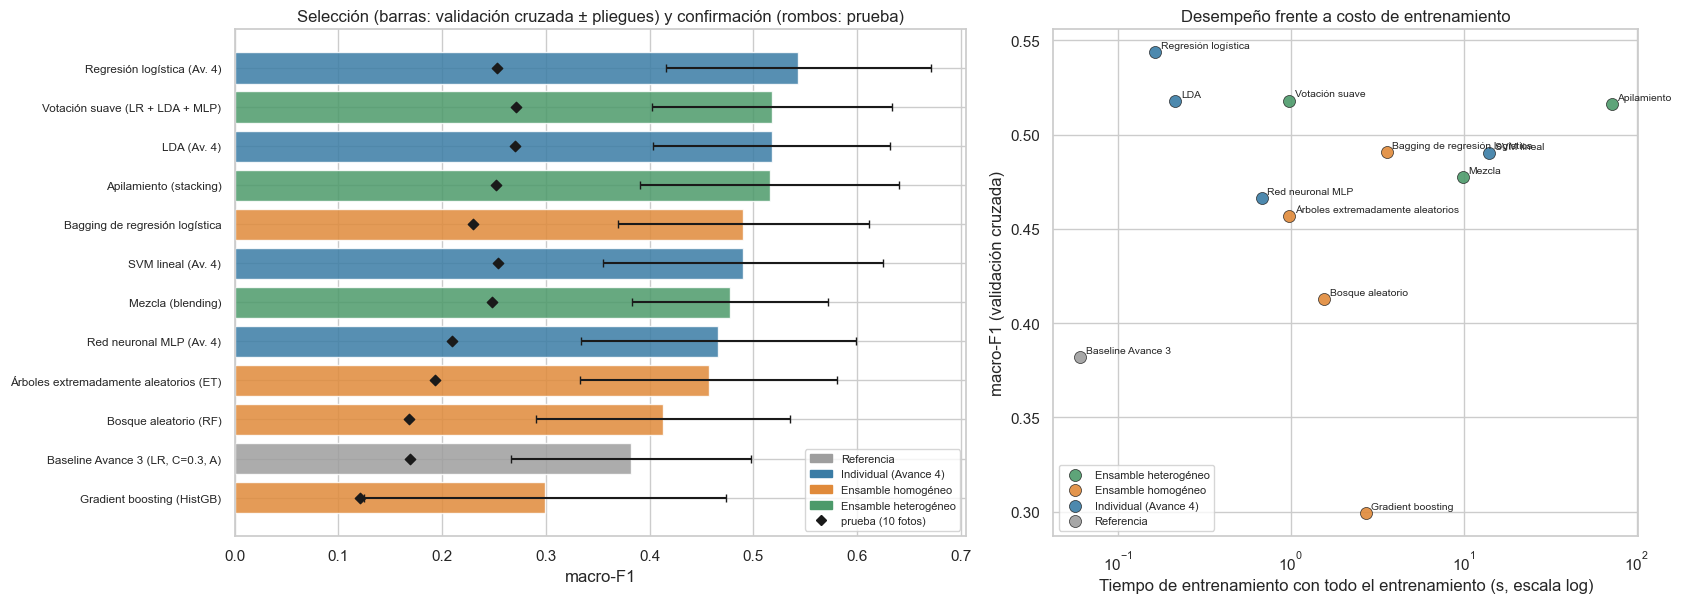

In [ ]:
res = pd.DataFrame(RESULTS).set_index("modelo")
BEST_IND = res[res.familia == "Individual (Avance 4)"].macroF1_CV.idxmax()          # mejor individual de la fase previa (por la métrica principal)
res["dif_vs_mejor_ind"] = [FOLDS[n].mean() - FOLDS[BEST_IND].mean() for n in res.index]
res["pliegues_ganados"] = [f"{int((FOLDS[n] > FOLDS[BEST_IND]).sum())}/{cv.n_splits}" for n in res.index]
res = res.sort_values("macroF1_CV", ascending=False); res.insert(0, "puesto", range(1, len(res) + 1))

print(f"Mejor individual de la fase previa: {BEST_IND} (macro-F1 CV {res.loc[BEST_IND, 'macroF1_CV']:.3f})\n")
print("A) SELECCIÓN — validación cruzada de 5 pliegues agrupada por foto (solo entrenamiento), ordenada por la métrica principal (macro-F1)")
display(res[["puesto", "familia", "macroF1_CV", "desv_CV", "bal_acc", "top3", "acc_línea", "t_fold_s", "t_entren_s", "dif_vs_mejor_ind", "pliegues_ganados"]]
        .rename(columns={"macroF1_CV": "macro-F1 CV", "desv_CV": "± pliegues", "bal_acc": "balanced acc", "top3": "top-3", "acc_línea": "exactitud línea",
                         "t_fold_s": "t. entren. por pliegue (s)", "t_entren_s": "t. entren. final (s)", "dif_vs_mejor_ind": "Δ vs mejor individual", "pliegues_ganados": "pliegues donde gana"}).round(3))
print("B) CONFIRMACIÓN — una sola evaluación en las 10 fotos de prueba (no se usó para elegir nada) y costo de inferencia")
display(res[["macroF1_test", "IC95_macroF1_test", "bal_acc_test", "top3_test", "acc_línea_test", "acc_marca_test", "error_conteo", "conteos_exactos", "ms_por_1000_prod", "tamaño_KB"]]
        .rename(columns={"macroF1_test": "macro-F1 prueba", "IC95_macroF1_test": "IC95 % (bootstrap de fotos)", "bal_acc_test": "balanced acc", "top3_test": "top-3", "acc_línea_test": "exactitud línea",
                         "acc_marca_test": "exactitud marca", "error_conteo": "error de conteo (piezas)", "conteos_exactos": "conteos exactos", "ms_por_1000_prod": "ms por 1000 prod.", "tamaño_KB": "tamaño (KB)"}).round(3))

palette = {"Referencia": "#9e9e9e", "Individual (Avance 4)": "#3a7ca5", FAM_HOMO: "#e08a3a", FAM_HETERO: "#4c9a6a"}
fig, axes = plt.subplots(1, 2, figsize=(17, 6.2), gridspec_kw={"width_ratios": [1.25, 1]})
ordr = res.index[::-1]; yy = np.arange(len(ordr))
axes[0].barh(yy, res.loc[ordr, "macroF1_CV"], xerr=res.loc[ordr, "desv_CV"], color=[palette[f] for f in res.loc[ordr, "familia"]], alpha=0.85, capsize=3)
axes[0].scatter(res.loc[ordr, "macroF1_test"], yy, color="k", marker="D", s=28, zorder=3, label="prueba (10 fotos)")
axes[0].set_yticks(yy); axes[0].set_yticklabels(ordr, fontsize=8.5); axes[0].set_xlabel("macro-F1"); axes[0].set_title("Selección (barras: validación cruzada ± pliegues) y confirmación (rombos: prueba)")
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()] + [plt.Line2D([], [], color="k", marker="D", ls="", ms=5)], labels=list(palette) + ["prueba (10 fotos)"], fontsize=8, loc="lower right")
for fam, g in res.groupby("familia"):
    axes[1].scatter(g.t_entren_s, g.macroF1_CV, s=75, color=palette[fam], label=fam, alpha=0.9, edgecolor="k", linewidth=0.5)
for n, r in res.iterrows():
    axes[1].annotate(n.split(" (")[0], (r.t_entren_s, r.macroF1_CV), fontsize=7.5, xytext=(4, 3), textcoords="offset points")
axes[1].set_xscale("log"); axes[1].set_xlabel("Tiempo de entrenamiento con todo el entrenamiento (s, escala log)"); axes[1].set_ylabel("macro-F1 (validación cruzada)")
axes[1].set_title("Desempeño frente a costo de entrenamiento"); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

**Lectura de la comparativa.**

1. **Ningún ensamble supera al mejor individual.** La regresión logística del Avance 4 queda en el primer lugar (0.544). Los mejores ensambles son la votación suave (0.518, **−0.026**, gana en 1 de 5 pliegues) y el apilamiento (0.516, **−0.028**, 0 de 5); siguen *bagging* (−0.053), mezcla (−0.066), ET (−0.087), bosque aleatorio (−0.131) y *gradient boosting* (−0.245).
2. **Todos menos uno superan al baseline del Avance 3** (0.382), pero la mejora viene de la **representación** (ConvNeXt-Tiny en E, Avance 4), no de combinar modelos. La regresión logística, el LDA, la SVM lineal y los ensambles de ellos rinden parecido porque trabajan sobre la misma información.
3. **Las desviaciones entre pliegues (≈ 0.12) son grandes**: nueve de los doce modelos están a una desviación del mejor. La comparación **pareada** (mismos pliegues) es más reveladora: ningún ensamble gana en 4 o más de los 5 pliegues.
4. **La prueba no cambia la conclusión.** Su rango es 0.12–0.27 y no sigue el orden de la validación cruzada (la votación, 0.272, y el LDA, 0.270, superan a la regresión logística, 0.253), pero los intervalos de incertidumbre se traslapan casi por completo (p. ej. votación [0.171, 0.512] y regresión logística [0.210, 0.456]): con 10 fotos no hay diferencia defendible. La prueba se ve mucho más baja que la validación cruzada (≈ 0.25 frente a ≈ 0.52) por la composición de esas fotos (§9).
5. **Utilidad práctica (prueba).** *Top-3* de 0.32–0.49 (el mejor es el LDA con 0.491; la regresión logística 0.472), exactitud de marca de 0.83–0.96 y de línea de 0.56–0.62. Los conteos exactos van de 9 % a 22 % (votación y LDA 22.4 %, regresión logística 16.7 %), muy lejos del 90 % que se propuso como meta; el error de conteo (2.6 a 3.4 piezas) no separa a los modelos.
6. **Costo.** Reentrenar la regresión logística toma 0.16 s, la votación 0.98 s, el *bagging* 3.59 s, la mezcla 9.84 s y el apilamiento 71.8 s (cada modelo base se ajusta 6 veces); el tamaño pasa de 1.8 MB a 10.3 MB (votación) y 11.3 MB (apilamiento), y la inferencia de 13 ms por 1 000 productos a 45 ms (votación), 51 ms (apilamiento) y 104 ms (*bagging*). Son costos pequeños en términos absolutos (el extractor ConvNeXt-Tiny, ≈ 0.3 s por producto, domina el tiempo de uso), pero **ninguno compra una mejora**.

### 7.1 ¿Se complementan los modelos base?

Un ensamble heterogéneo solo ayuda si sus miembros **se equivocan en productos distintos**. Se mide el acuerdo entre las predicciones de los cuatro individuales en la prueba y cuántos productos acierta *al menos uno* (el "oráculo", un techo para cualquier combinación de ellos).

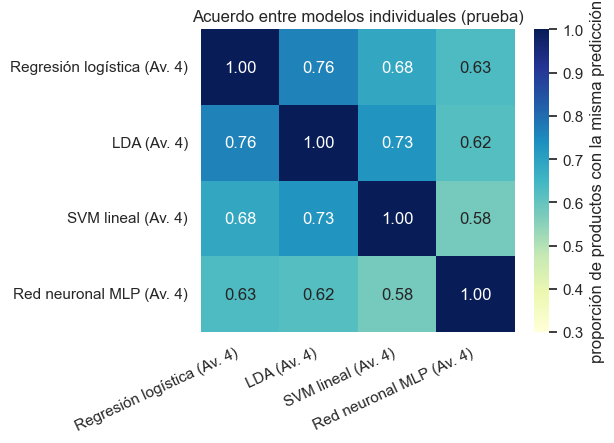

Exactitud de cada individual en prueba: {'Regresión logística': 0.329, 'LDA': 0.329, 'SVM lineal': 0.304, 'Red neuronal MLP': 0.292}
Oráculo (al menos uno acierta): 0.385 | los cuatro aciertan: 0.242 | solo uno acierta: 0.056
Votación por mayoría simple de los cuatro, exactitud: 0.329


In [ ]:
# ¿Se complementan los cuatro individuales? Acuerdo entre sus predicciones en prueba y "oráculo" (¿alguno acierta?).
inds = [n for n in res.index if res.loc[n, "familia"] == "Individual (Avance 4)"]
agree = pd.DataFrame([[np.mean(PREDS[a] == PREDS[b]) for b in inds] for a in inds], index=inds, columns=inds)
correct = np.array([PREDS[n] == yte for n in inds])
fig, ax = plt.subplots(figsize=(6.2, 4.6)); sns.heatmap(agree, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0.3, vmax=1, ax=ax, cbar_kws={"label": "proporción de productos con la misma predicción"})
ax.set_title("Acuerdo entre modelos individuales (prueba)"); plt.setp(ax.get_xticklabels(), rotation=25, ha="right"); fig.tight_layout(); plt.show()
print("Exactitud de cada individual en prueba:", {n.split(" (")[0]: round(float(c.mean()), 3) for n, c in zip(inds, correct)})
print(f"Oráculo (al menos uno acierta): {correct.any(0).mean():.3f} | los cuatro aciertan: {correct.all(0).mean():.3f} | solo uno acierta: {(correct.sum(0) == 1).mean():.3f}")
print(f"Votación por mayoría simple de los cuatro, exactitud: {np.mean([Counter(col).most_common(1)[0][0] == t for col, t in zip(np.array([PREDS[n] for n in inds]).T, yte)]):.3f}")

**Lectura.** Los cuatro modelos coinciden en entre el 58 % y el 76 % de sus predicciones: se parecen, pero no son idénticos. Sin embargo, el "oráculo" (que al menos uno acierte) es de **0.385** frente a **0.329** del mejor individual: aun eligiendo siempre al modelo correcto, la ganancia máxima sería de ≈ 6 puntos de exactitud. Y solo en el **5.6 %** de los productos exactamente un modelo acierta (que es donde un ensamble podría ayudar); en el 24.2 % aciertan los cuatro y en el **61.5 % no acierta ninguno**. La votación por mayoría de los cuatro da 0.329, igual que el mejor individual. Los errores son en su mayoría **compartidos**: son modelos lineales entrenados sobre la misma representación y fallan en los mismos productos (presentaciones casi idénticas). Un ensamble no puede corregir errores que todos sus miembros cometen.

### 7.2 ¿Ayuda combinar *representaciones* distintas?

En el Avance 4 la representación pesó más que el algoritmo. Una segunda fuente de diversidad es entonces entrenar el mismo algoritmo sobre **vistas distintas** del producto (características a mano **A**, *embedding* de ConvNeXt **D**, ambas juntas **E**) y promediar sus probabilidades. Se evalúa con los mismos 5 pliegues (regresión logística con C fijo, solo con entrenamiento).

In [ ]:
# Otra fuente de diversidad: promediar modelos entrenados sobre REPRESENTACIONES distintas (características a mano A, ConvNeXt D) frente a un solo modelo sobre E = A + D.
def lr_view(Xv, C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight="balanced", max_iter=2000)).fit(Xv[tr_], ytr_)
rows_ = {"LR sobre E (A + D)": [], "Promedio LR sobre A + LR sobre D": [], "Promedio LR sobre A + LR sobre D + LR sobre E": []}
for tr_, va_ in cv.split(X_E[train_idx], ytr, gtr):
    ytr_, yva_ = ytr[tr_], ytr[va_]; cl_ = np.unique(ytr_)
    P = {v: lr_view(Xv[train_idx], C).predict_proba(Xv[train_idx][va_]) for v, (Xv, C) in {"A": (X_A, 0.3), "D": (X_D, 1.0), "E": (X_E, 1.0)}.items()}
    for name, ks in [("LR sobre E (A + D)", "E"), ("Promedio LR sobre A + LR sobre D", "AD"), ("Promedio LR sobre A + LR sobre D + LR sobre E", "ADE")]:
        rows_[name].append(macro_f1(yva_, cl_[sum(P[k] for k in ks).argmax(1)]))
display(pd.DataFrame({k: [np.mean(v), np.std(v)] for k, v in rows_.items()}, index=["macroF1_CV", "desv"]).T.round(3))

,macroF1_CV,desv
LR sobre E (A + D),0.530,0.117
Promedio LR sobre A + LR sobre D,0.531,0.124
Promedio LR sobre A + LR sobre D + LR sobre E,0.539,0.139


**Lectura.** Promediar regresiones logísticas sobre las vistas A y D da 0.531 ± 0.124, y sobre A, D y E, 0.539 ± 0.139, frente a 0.530 ± 0.117 de una sola regresión logística sobre E (A + D). La diferencia (≤ 0.009) es mínima frente a la desviación entre pliegues (≈ 0.12). Es coherente con el Avance 4, donde agregar las características a mano al *embedding* sumó apenas ≈ 0.02: la **diversidad de representaciones** tampoco crea información nueva, porque las 92 características a mano casi no aportan una vez que se tiene el *embedding* (se confirma en §9.4).

## 8. Selección del modelo final

La métrica principal no basta. El sistema debe **identificar el producto de cada caja para contar existencias por foto**, en un contexto veterinario donde confundir una dosis tiene consecuencias. Los criterios que se ponderan son:

1. **Desempeño y estabilidad** (macro-F1 de validación cruzada, ventaja pareada sobre el mejor individual, desviación entre pliegues).
2. **Utilidad práctica:** top-3 (un operador confirma entre pocas opciones), exactitud por línea y marca, y error de conteo.
3. **Probabilidades por clase**, para marcar productos dudosos y enviarlos a revisión.
4. **Costo:** tiempo de entrenamiento (se reentrena cuando llegan etiquetas nuevas), tamaño del modelo y latencia de inferencia (el costo dominante sigue siendo el extractor ConvNeXt-Tiny, ≈ 0.3 s por producto en CPU).
5. **Interpretabilidad y simplicidad de despliegue.**

Regla de decisión: se parte del modelo con mayor macro-F1 de validación cruzada y se consideran **candidatos** los que están a **una desviación estándar** de él (misma regla del Avance 4). Entre ellos, un ensamble solo desplaza al mejor individual si su ventaja es **consistente** (gana en al menos 4 de los 5 pliegues pareados); si no, el costo y la opacidad adicionales no se justifican. La prueba **no interviene en la decisión**: solo la confirma.

In [ ]:
top_cv = res.macroF1_CV.max(); top_sd = res.loc[res.macroF1_CV.idxmax(), "desv_CV"]
INTERP = {"Regresión logística (Av. 4)": "alta (coeficientes por clase)", "LDA (Av. 4)": "alta (direcciones discriminantes)", "SVM lineal (Av. 4)": "media-alta (pesos lineales)",
          "Red neuronal MLP (Av. 4)": "baja", "Bosque aleatorio (RF)": "media (importancias, muchos árboles)", "Árboles extremadamente aleatorios (ET)": "media (importancias, muchos árboles)",
          "Bagging de regresión logística": "media (promedio de modelos lineales)", "Gradient boosting (HistGB)": "baja", "Votación suave (LR + LDA + MLP)": "media-baja",
          "Apilamiento (stacking)": "baja", "Mezcla (blending)": "baja"}
res["interpretabilidad"] = pd.Series(INTERP)
short = res[res.macroF1_CV >= top_cv - top_sd]
print(f"Mejor macro-F1 en validación cruzada: {top_cv:.3f} ± {top_sd:.3f} ({res.macroF1_CV.idxmax()}). Modelos a una desviación o menos de él: {len(short)} de {len(res)}")
display(short[["familia", "macroF1_CV", "desv_CV", "pliegues_ganados", "bal_acc", "top3", "acc_línea", "t_entren_s", "ms_por_1000_prod", "tamaño_KB", "interpretabilidad"]].round(3))

Mejor macro-F1 en validación cruzada: 0.544 ± 0.128 (Regresión logística (Av. 4)). Modelos a una desviación o menos de él: 9 de 12


,familia,macroF1_CV,desv_CV,pliegues_ganados,bal_acc,top3,acc_línea,t_entren_s,ms_por_1000_prod,tamaño_KB,interpretabilidad
modelo,,,,,,,,,,,
Regresión logística (Av. 4),Individual (Avance 4),0.544,0.128,0/5,0.580,0.702,0.913,0.165,12.783,1838.092,alta (coeficientes por clase)
Votación suave (LR + LDA + MLP),Ensamble heterogéneo,0.518,0.116,1/5,0.562,0.681,0.896,0.978,44.938,10591.853,media-baja
LDA (Av. 4),Individual (Avance 4),0.518,0.114,1/5,0.563,0.695,0.902,0.215,23.186,5909.797,alta (direcciones discriminantes)
Apilamiento (stacking),Ensamble heterogéneo,0.516,0.125,0/5,0.554,0.680,0.908,71.771,50.771,11593.956,baja
Bagging de regresión logística,Ensamble homogéneo,0.491,0.121,0/5,0.531,0.682,0.913,3.595,104.067,5755.289,media (promedio de modelos lineales)
SVM lineal (Av. 4),Individual (Avance 4),0.490,0.135,0/5,0.531,0.657,0.820,14.070,4.373,298.191,media-alta (pesos lineales)
Mezcla (blending),Ensamble heterogéneo,0.478,0.095,1/5,0.531,0.561,0.866,9.841,43.503,8877.681,baja
Red neuronal MLP (Av. 4),Individual (Avance 4),0.466,0.133,0/5,0.491,0.631,0.880,0.679,6.908,2855.980,baja
Árboles extremadamente aleatorios (ET),Ensamble homogéneo,0.457,0.124,0/5,0.497,0.654,0.897,0.978,70.721,24794.725,"media (importancias, muchos árboles)"


**Resultado.** Nueve de los doce modelos quedan a una desviación estándar del mejor (0.544 ± 0.128 → ≥ 0.416), porque la desviación entre pliegues es grande. Pero la columna *pliegues donde gana* muestra que **ningún ensamble** supera a la regresión logística de forma consistente: la votación y la mezcla ganan en 1 de 5 pliegues y los demás en 0 de 5, además de tener un macro-F1 medio menor. Por la regla fijada, ningún ensamble desplaza al mejor individual. La celda siguiente aplica la regla.

In [ ]:
# Regla de §8 (fijada antes de mirar la prueba): un ensamble solo desplaza al mejor individual si está entre los candidatos Y gana en al menos 4 de los 5 pliegues pareados.
wins = res.pliegues_ganados.str.split("/").str[0].astype(int)
cand = short[short.familia != "Referencia"].copy(); cand["pliegues_ganados_n"] = wins[cand.index]
cand["desplaza_al_mejor_individual"] = cand.familia.str.startswith("Ensamble") & (cand.pliegues_ganados_n >= 4) & (cand.macroF1_CV > res.loc[BEST_IND, "macroF1_CV"])
display(cand[["familia", "macroF1_CV", "dif_vs_mejor_ind", "pliegues_ganados", "desplaza_al_mejor_individual"]].round(3))
winners = cand[cand.desplaza_al_mejor_individual]
FINAL_NAME = winners.macroF1_CV.idxmax() if len(winners) else BEST_IND
print(f"Ensambles que desplazan al mejor individual ({BEST_IND}): {list(winners.index) if len(winners) else 'ninguno'}")
print(f"MODELO FINAL: {FINAL_NAME}")

,familia,macroF1_CV,dif_vs_mejor_ind,pliegues_ganados,desplaza_al_mejor_individual
modelo,,,,,
Regresión logística (Av. 4),Individual (Avance 4),0.544,0.000,0/5,False
Votación suave (LR + LDA + MLP),Ensamble heterogéneo,0.518,-0.026,1/5,False
LDA (Av. 4),Individual (Avance 4),0.518,-0.026,1/5,False
Apilamiento (stacking),Ensamble heterogéneo,0.516,-0.028,0/5,False
Bagging de regresión logística,Ensamble homogéneo,0.491,-0.053,0/5,False
SVM lineal (Av. 4),Individual (Avance 4),0.490,-0.053,0/5,False
Mezcla (blending),Ensamble heterogéneo,0.478,-0.066,1/5,False
Red neuronal MLP (Av. 4),Individual (Avance 4),0.466,-0.077,0/5,False
Árboles extremadamente aleatorios (ET),Ensamble homogéneo,0.457,-0.087,0/5,False


Ensambles que desplazan al mejor individual (Regresión logística (Av. 4)): ninguno
MODELO FINAL: Regresión logística (Av. 4)


### Modelo final: regresión logística sobre E (C ≈ 15.9, pesos de clase balanceados, PCA a 256 componentes)

Es el modelo individual del Avance 4, que **ningún ensamble de este avance logra superar**. Argumentos:

1. **Desempeño.** Mayor macro-F1 de validación cruzada (0.544 ± 0.128); el mejor ensamble (votación suave) queda 0.026 por debajo y solo gana en 1 de 5 pliegues pareados. En la prueba (confirmación independiente) su macro-F1 es 0.253 [0.210, 0.456], estadísticamente indistinguible del de la votación (0.272), el LDA (0.270) o el apilamiento (0.252).
2. **Un ensamble solo se justifica si aporta algo.** Aquí cuesta más y no mejora: el apilamiento tarda 435 veces más en entrenarse que la regresión logística, ocupa 6.3 veces más (11.3 frente a 1.8 MB) y tarda 4.0 veces más en predecir; la votación pesa 5.8 veces más y predice 3.5 veces más lento. Los miembros se equivocan en los mismos productos (§7.1) y el metamodelo del apilamiento confía casi solo en la regresión logística (§6.2).
3. **Probabilidades por clase y revisión humana.** La regresión logística entrega probabilidades de forma nativa y con ellas se puede mandar a revisión humana lo que el modelo duda (§9.6). Las probabilidades del apilamiento y de la mezcla son una transformación de puntajes de un metamodelo y las de la votación mezclan modelos con calibraciones distintas.
4. **Interpretabilidad.** Los coeficientes por clase y variable permiten auditar por qué se confunden dos presentaciones; en un contexto veterinario, donde un error de dosis tiene consecuencias, explicar la decisión importa. Los ensambles de arriba la pierden (opacidad *media-baja* a *baja*).
5. **Alineación con el negocio.** Los errores (§9) vienen de presentaciones casi idénticas de Bravecto que difieren en el texto del empaque y de líneas casi ausentes del entrenamiento. Es un problema de **información**, no de varianza del modelo: combinar más modelos lineales sobre los mismos datos no lo resuelve, y sí multiplica el costo de entrenar, almacenar y servir.

**Plan B y qué cambiaría la decisión.** Si el negocio prefiere un modelo con la menor varianza posible y acepta ≈ 6 veces más tamaño, la **votación suave** (LR + LDA + MLP) es la alternativa más defendible: la más cercana en validación cruzada (−0.026) y la de mejor macro-F1 de prueba entre los ensambles (0.272). La comparación debe repetirse cuando existan miembros realmente **diversos** (p. ej., una CNN afinada de extremo a extremo o un lector de texto del empaque): ahí un apilamiento sí podría aportar.

## 9. Gráficos del modelo final

Todos se calculan sobre las **10 fotos de prueba** (161 productos), que el modelo nunca vio, y se leen con las advertencias del Avance 4: hay 3 clases que el entrenamiento no contiene (14 productos que nadie podría acertar), varias clases tienen muy pocos ejemplos y con solo 10 fotos cualquier cifra tiene una incertidumbre grande.

In [ ]:
final_est, final_X = FITTED[FINAL_NAME]
proba = final_est.predict_proba(final_X[test_idx]); classes = final_est.classes_
pred_f = classes[proba.argmax(1)]; ok = pred_f == yte; conf = proba.max(1)
assert (pred_f == PREDS[FINAL_NAME]).all()
fr = res.loc[FINAL_NAME]
print(f"MODELO FINAL: {FINAL_NAME}\nPrueba ({len(yte)} productos, {len(set(gte))} fotos): macro-F1 {fr.macroF1_test:.3f} {fr.IC95_macroF1_test} | top-3 {fr.top3_test:.3f} | línea {fr.acc_línea_test:.3f} | marca {fr.acc_marca_test:.3f} | "
      f"exactitud {ok.mean():.3f} | error de conteo {fr.error_conteo:.2f} piezas | conteos exactos {fr.conteos_exactos:.1%}")

MODELO FINAL: Regresión logística (Av. 4)
Prueba (161 productos, 10 fotos): macro-F1 0.253 [0.210, 0.456] | top-3 0.472 | línea 0.602 | marca 0.944 | exactitud 0.329 | error de conteo 2.86 piezas | conteos exactos 16.7%


### 9.1 Matriz de confusión y F1 por producto

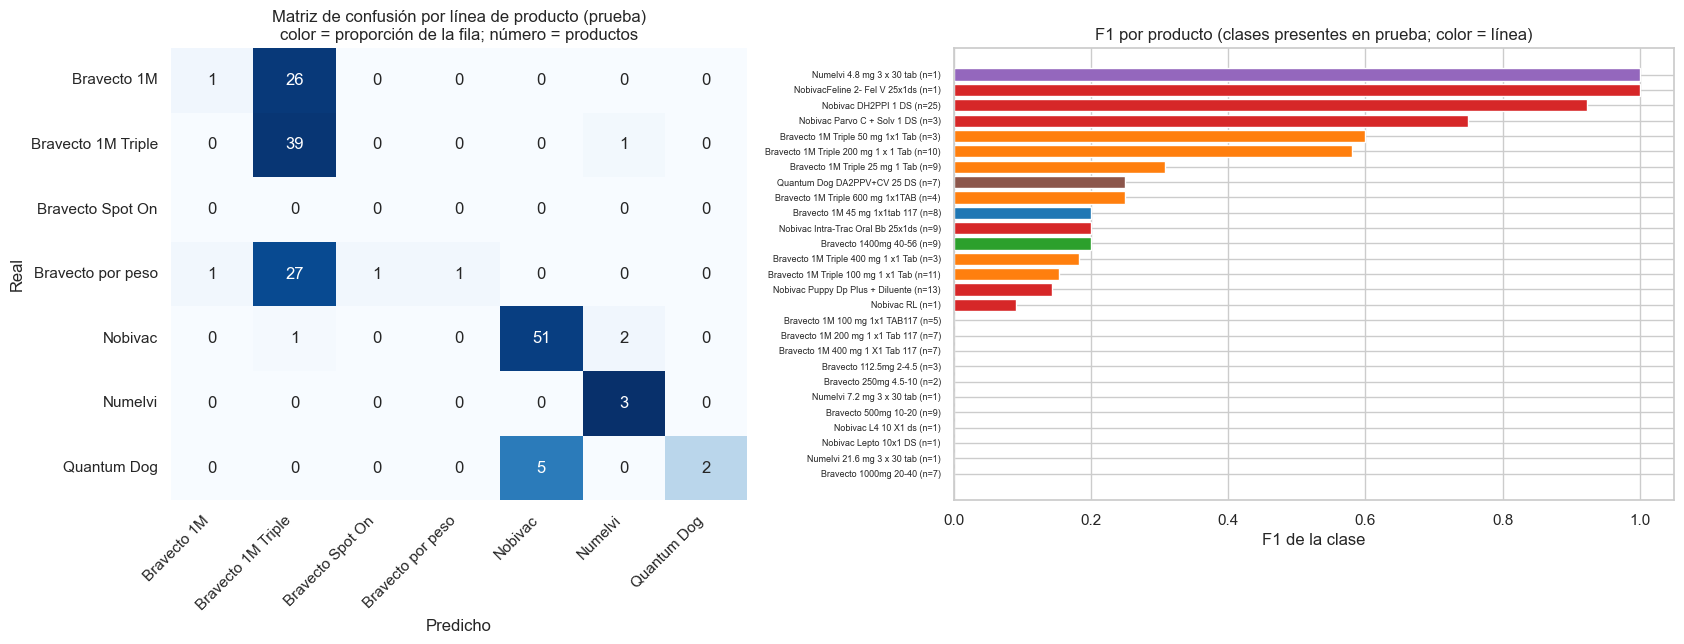

Errores: 108 de 161 (67.1%) | dentro de la misma línea: 40.7% | misma marca: 91.7%
Productos con F1 = 0: 11 de 27 | con F1 ≥ 0.5: 6


,,veces
real,predicho,
Nobivac Puppy Dp Plus + Diluente,Nobivac RL,10
Bravecto 500mg 10-20,Bravecto 1M Triple 200 mg 1 x 1 Tab,8
Bravecto 1000mg 20-40,Bravecto 1M Triple 400 mg 3 Tab,5
Quantum Dog DA2PPV+CV 25 DS,Nobivac RL,5
Bravecto 1M Triple 100 mg 1 x1 Tab,Bravecto 1M Triple 600 mg 1x1TAB,5
Nobivac Intra-Trac Oral Bb 25x1ds,Nobivac RL,4
Bravecto 1M 200 mg 1 x1 Tab 117,Bravecto 1M Triple 25 mg 3 tab,4
Bravecto 1M 45 mg 1x1tab 117,Bravecto 1M Triple 400 mg 3 Tab,4


In [ ]:
lines = sorted(set(map(linea, yte)) | set(map(linea, pred_f)))
cm = confusion_matrix([linea(c) for c in yte], [linea(c) for c in pred_f], labels=lines)
labs = sorted(set(yte)); f1s = pd.Series(f1_score(yte, pred_f, labels=labs, average=None, zero_division=0), index=labs); sup = pd.Series(Counter(yte)).reindex(labs)
fig, axes = plt.subplots(1, 2, figsize=(17, 6.6), gridspec_kw={"width_ratios": [1, 1.25]})
sns.heatmap(cm / cm.sum(1, keepdims=True).clip(1), annot=cm, fmt="d", cmap="Blues", xticklabels=lines, yticklabels=lines, ax=axes[0], cbar=False)
axes[0].set_title("Matriz de confusión por línea de producto (prueba)\ncolor = proporción de la fila; número = productos"); axes[0].set_xlabel("Predicho"); axes[0].set_ylabel("Real"); plt.setp(axes[0].get_xticklabels(), rotation=45, ha="right")
order = f1s.sort_values().index
axes[1].barh(range(len(order)), f1s[order], color=[sns.color_palette("tab10")[sorted(set(map(linea, labs))).index(linea(c))] for c in order])
axes[1].set_yticks(range(len(order))); axes[1].set_yticklabels([f"{c} (n={sup[c]})" for c in order], fontsize=6.5); axes[1].set_xlabel("F1 de la clase"); axes[1].set_title("F1 por producto (clases presentes en prueba; color = línea)")
fig.tight_layout(); plt.show()
err = pd.DataFrame({"real": yte, "predicho": pred_f}); err = err[err.real != err.predicho]
print(f"Errores: {len(err)} de {len(yte)} ({len(err) / len(yte):.1%}) | dentro de la misma línea: {np.mean([linea(a) == linea(b) for a, b in zip(err.real, err.predicho)]):.1%} | misma marca: {np.mean([marca(a) == marca(b) for a, b in zip(err.real, err.predicho)]):.1%}")
print(f"Productos con F1 = 0: {(f1s == 0).sum()} de {len(f1s)} | con F1 ≥ 0.5: {(f1s >= 0.5).sum()}")
display(err.groupby(["real", "predicho"]).size().sort_values(ascending=False).head(8).rename("veces").to_frame())

**Interpretación.**

- **A nivel de marca el modelo funciona; a nivel de presentación no.** El 91.7 % de los errores ocurre dentro de la misma marca (exactitud de marca 0.944) y solo el 40.7 % dentro de la misma línea. *Nobivac* se reconoce bien (51 de 54 productos); *Numelvi* (3 de 3) también.
- **Colapso de Bravecto sobre *1M Triple*.** De los 27 productos de la línea *Bravecto 1M* y los 30 de *Bravecto por peso* en la prueba, **26 y 27 se predicen como *Bravecto 1M Triple***. La razón está en los datos: en entrenamiento hay 193 productos de *1M Triple* pero solo 20 de *Bravecto 1M* y **2 de *Bravecto por peso***, mientras que las 10 fotos de prueba contienen 27 y 30. Ante cajas de líneas que casi no vio, el modelo responde con la línea que mejor conoce. Es un desbalance entre entrenamiento y prueba, no un fallo del algoritmo: ninguno de los 11 modelos comparados pasa de 0.62 de exactitud de línea en la prueba (tabla B de §7).
- ***Quantum Dog*** (vacunas): 5 de 7 se confunden con *Nobivac*, también del segmento de vacunas.
- **F1 por producto:** 11 de las 27 clases presentes en prueba tienen F1 = 0 y solo 6 llegan a 0.5. Los mejores son *Nobivac DH2PPI* (n = 25, F1 ≈ 0.92) y *Nobivac Parvo* (n = 3, 0.75); las clases de una sola caja (*Numelvi 4.8 mg*, *Nobivac Feline*) alcanzan 1.0 pero con un solo ejemplo no son concluyentes. Los errores más repetidos: *Nobivac Puppy* → *Nobivac RL* (10 veces) y *Bravecto 500 mg* → *1M Triple 200 mg* (8).
- **Implicación:** para el inventario, el sistema es confiable para saber *qué marca* hay en el anaquel, pero no para distinguir dosis de Bravecto sin información adicional (texto del empaque) y sin más ejemplos de las líneas subrepresentadas.

### 9.2 Curva ROC

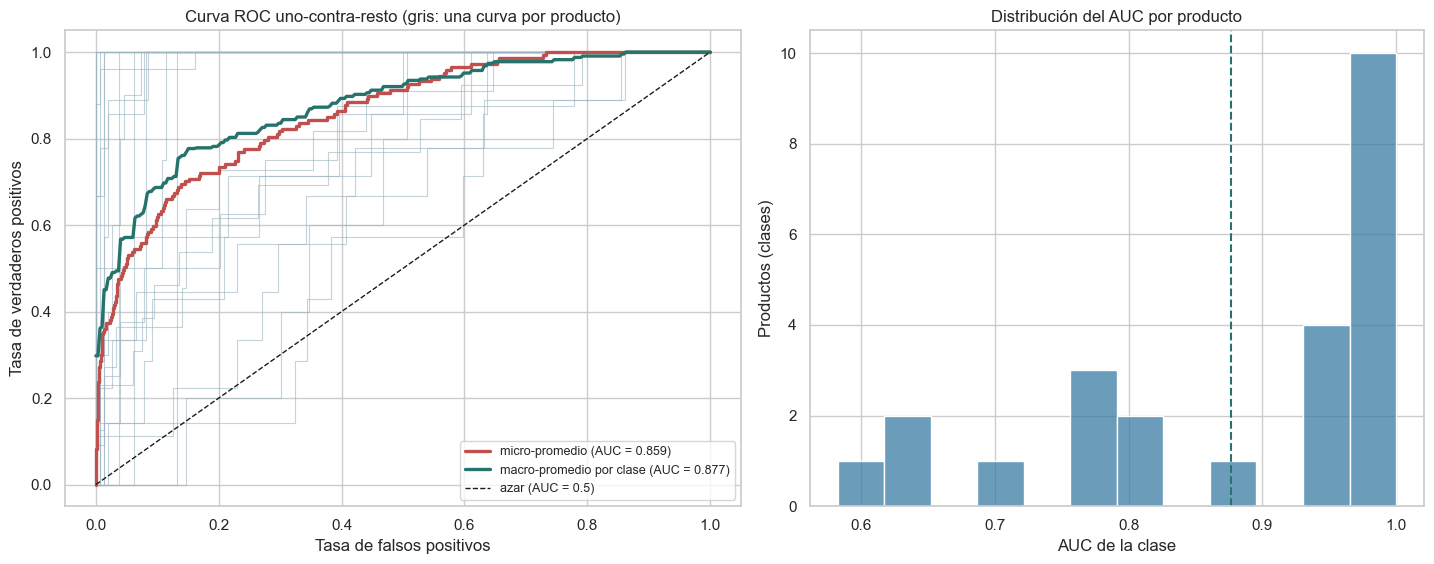

AUC micro 0.859 | AUC macro (uno-contra-resto, 24 clases presentes en prueba) 0.877 | clases con AUC ≥ 0.9: 58% | AUC < 0.7: ['Bravecto 1000mg 20-40', 'Bravecto 1400mg 40-56', 'Bravecto 1M 100 mg 1x1 TAB117']


In [ ]:
Y = label_binarize(yte, classes=classes)                 # una fila por producto de prueba; las clases ausentes en entrenamiento quedan como negativos en todas las columnas
present = np.where(Y.sum(0) > 0)[0]                       # clases con al menos un positivo en prueba (las únicas donde la curva está definida)
fpr_mi, tpr_mi, _ = roc_curve(Y.ravel(), proba.ravel()); auc_mi = auc(fpr_mi, tpr_mi)
curves = {k: roc_curve(Y[:, k], proba[:, k])[:2] for k in present}; aucs = pd.Series({classes[k]: auc(*curves[k]) for k in present})
grid = np.linspace(0, 1, 300); tpr_macro = np.mean([np.interp(grid, *curves[k]) for k in present], axis=0); auc_macro = aucs.mean()
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8), gridspec_kw={"width_ratios": [1.1, 1]})
for k in present: axes[0].plot(*curves[k], color="#9db4c0", lw=0.8, alpha=0.6)
axes[0].plot(fpr_mi, tpr_mi, color="#c0504d", lw=2.4, label=f"micro-promedio (AUC = {auc_mi:.3f})")
axes[0].plot(grid, tpr_macro, color="#26736b", lw=2.4, label=f"macro-promedio por clase (AUC = {auc_macro:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="azar (AUC = 0.5)"); axes[0].set_xlabel("Tasa de falsos positivos"); axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].set_title("Curva ROC uno-contra-resto (gris: una curva por producto)"); axes[0].legend(loc="lower right", fontsize=9)
sns.histplot(aucs, bins=12, color="#3a7ca5", ax=axes[1]); axes[1].axvline(auc_macro, color="#26736b", ls="--"); axes[1].set_xlabel("AUC de la clase"); axes[1].set_ylabel("Productos (clases)")
axes[1].set_title("Distribución del AUC por producto")
fig.tight_layout(); plt.show()
print(f"AUC micro {auc_mi:.3f} | AUC macro (uno-contra-resto, {len(present)} clases presentes en prueba) {auc_macro:.3f} | clases con AUC ≥ 0.9: {(aucs >= 0.9).mean():.0%} | AUC < 0.7: {list(aucs[aucs < 0.7].index)}")

**Interpretación.**

- La curva ROC micro-promedio tiene un AUC de **0.859** y la macro-promedio de **0.877** (24 clases con al menos un positivo en prueba): el modelo **ordena bien** los productos, es decir, el puntaje de la clase correcta suele ser mayor que el de la mayoría de las demás aunque no siempre sea el más alto. Esto es coherente con que el *top-3* (0.472) sea bastante mayor que la exactitud *top-1* (0.329).
- **Por producto**, 14 de las 24 clases (58 %) tienen un AUC ≥ 0.9 y 10 están prácticamente en 1.0 (histograma). Tres quedan por debajo de 0.7, casi al nivel del azar: *Bravecto 1000 mg 20-40*, *Bravecto 1400 mg 40-56* y *Bravecto 1M 100 mg*, presentaciones que el modelo no logra separar de las demás de su línea (§9.1).
- **Cuidado al leerla.** Con 41 clases, los negativos de cada curva son ≈ 40 veces más numerosos que los positivos, lo que hace que el AUC luzca optimista; por eso el macro-F1 (0.253) y el AUC (0.88) no se contradicen: el AUC mide el orden de los puntajes, no si la decisión final (el máximo) es correcta. La curva de precisión-recall (siguiente gráfico) es más exigente.

### 9.3 Curva de precisión-recall

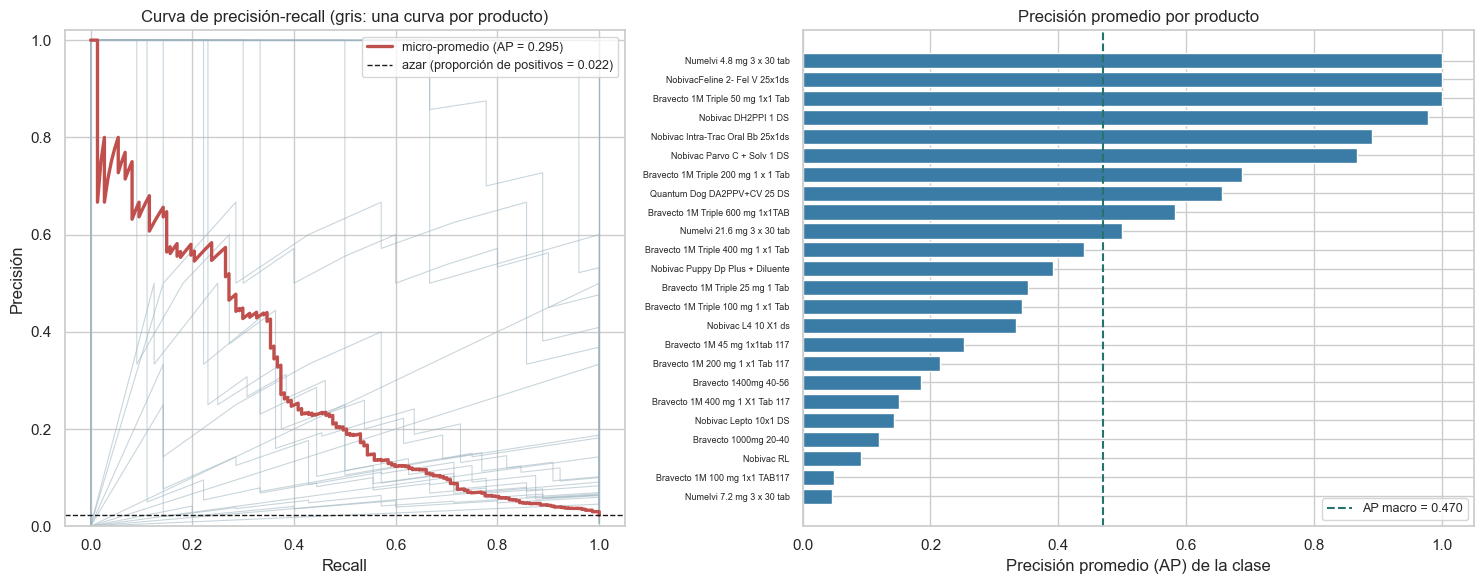

AP micro 0.295 (azar 0.022) | AP macro 0.470 | clases con AP ≥ 0.5: 42% | AP < 0.1: 3 clases


In [ ]:
p_mi, r_mi, _ = precision_recall_curve(Y.ravel(), proba.ravel()); ap_mi = average_precision_score(Y.ravel(), proba.ravel())
aps = pd.Series({classes[k]: average_precision_score(Y[:, k], proba[:, k]) for k in present}); prev = Y.sum() / Y.size
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.2]})
for k in present:
    p_, r_, _ = precision_recall_curve(Y[:, k], proba[:, k]); axes[0].plot(r_, p_, color="#9db4c0", lw=0.8, alpha=0.55)
axes[0].plot(r_mi, p_mi, color="#c0504d", lw=2.4, label=f"micro-promedio (AP = {ap_mi:.3f})")
axes[0].axhline(prev, color="k", ls="--", lw=1, label=f"azar (proporción de positivos = {prev:.3f})"); axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precisión")
axes[0].set_title("Curva de precisión-recall (gris: una curva por producto)"); axes[0].legend(fontsize=9); axes[0].set_ylim(0, 1.02)
o = aps.sort_values(); axes[1].barh(range(len(o)), o.values, color="#3a7ca5"); axes[1].set_yticks(range(len(o))); axes[1].set_yticklabels(o.index, fontsize=6.5)
axes[1].axvline(aps.mean(), color="#26736b", ls="--", label=f"AP macro = {aps.mean():.3f}"); axes[1].set_xlabel("Precisión promedio (AP) de la clase"); axes[1].set_title("Precisión promedio por producto"); axes[1].legend(fontsize=9)
fig.tight_layout(); plt.show()
print(f"AP micro {ap_mi:.3f} (azar {prev:.3f}) | AP macro {aps.mean():.3f} | clases con AP ≥ 0.5: {(aps >= 0.5).mean():.0%} | AP < 0.1: {(aps < 0.1).sum()} clases")

**Interpretación.**

- La **precisión promedio** micro es de **0.295**, unas 13 veces el azar (0.022), y la macro de **0.470**: el modelo recupera información útil, pero con costos claros. En la curva micro-promedio, con un *recall* de 0.2 la precisión es de ≈ 0.6 y, al recuperar el 40 % de los productos, baja a ≈ 0.25–0.3: **cada punto de *recall* adicional se paga con muchos falsos positivos**.
- Por producto: el 42 % de las clases tiene AP ≥ 0.5 (*Numelvi 4.8 mg*, *Nobivac Feline*, *Bravecto 1M Triple 50 mg* y *Nobivac DH2PPI* con AP ≈ 1; *Nobivac Intra-Trac* y *Nobivac Parvo* ≈ 0.9) y tres clases quedan por debajo de 0.1 (*Numelvi 7.2 mg*, *Bravecto 1M 100 mg* y *Nobivac RL*). Es la misma separación entre productos bien diferenciados y presentaciones casi idénticas que mostró la matriz de confusión.
- **Lectura para el negocio:** si se quisiera un listado automático con pocos falsos positivos, solo sería utilizable con umbrales altos y para los productos de las clases con AP alto; para el resto se necesita revisión (§9.6).

### 9.4 Importancia de las características

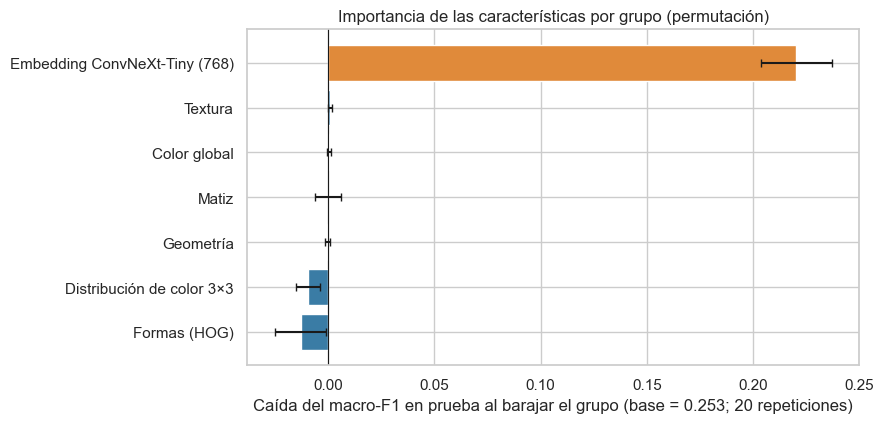

,caída_macroF1,desv,n_columnas
Formas (HOG),-0.013,0.012,32.0
Distribución de color 3×3,-0.010,0.006,27.0
Geometría,-0.001,0.001,7.0
Matiz,-0.000,0.006,12.0
Color global,0.000,0.001,10.0
Textura,0.001,0.001,4.0
Embedding ConvNeXt-Tiny (768),0.220,0.017,768.0


In [ ]:
# Importancia por permutación en bloques: se barajan juntas (entre productos) las columnas de un grupo de características y se mide cuánto cae el macro-F1 en prueba.
BLOCKS = {}
for j, c in enumerate(FEATURES): BLOCKS.setdefault(GROUP_OF[c], []).append(j)
BLOCKS["Embedding ConvNeXt-Tiny (768)"] = list(range(len(FEATURES), len(FEATURES) + X_D.shape[1]))
Xt = final_X[test_idx].copy(); base_f1 = macro_f1(yte, final_est.predict(Xt)); rng = np.random.default_rng(SEED); imp = {}
for block, cols in BLOCKS.items():
    drops = []
    for _ in range(20):
        Xp = Xt.copy(); Xp[:, cols] = Xt[rng.permutation(len(Xt))][:, cols]; drops.append(base_f1 - macro_f1(yte, final_est.predict(Xp)))
    imp[block] = (np.mean(drops), np.std(drops), len(cols))
imp = pd.DataFrame(imp, index=["caída_macroF1", "desv", "n_columnas"]).T.sort_values("caída_macroF1")
fig, ax = plt.subplots(figsize=(9, 4.4)); ax.barh(imp.index, imp.caída_macroF1, xerr=imp.desv, color=["#e08a3a" if i.startswith("Embedding") else "#3a7ca5" for i in imp.index], capsize=3)
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel(f"Caída del macro-F1 en prueba al barajar el grupo (base = {base_f1:.3f}; 20 repeticiones)"); ax.set_title("Importancia de las características por grupo (permutación)")
fig.tight_layout(); plt.show()
display(imp.round(3))

**Interpretación.**

- Barajar el bloque del *embedding* de ConvNeXt-Tiny **hunde el macro-F1 en prueba en ≈ 0.22** (de 0.253 a prácticamente 0). Barajar cualquiera de los seis grupos de características a mano **no lo reduce** (las caídas son ≈ 0; HOG y la distribución de color 3×3 incluso mejoran en ≈ 0.01 al barajarlos, dentro del ruido).
- **El modelo se apoya casi por completo en el *embedding*.** Es coherente con el Avance 4 (E frente a D: +0.02, dentro del ruido) y con §7.2: las 92 características a mano casi no aportan una vez que se tiene el *embedding*. Parte de la razón es la propia arquitectura: el PCA a 256 componentes conserva sobre todo la varianza de las 768 dimensiones del *embedding*, que dominan a las 92 columnas a mano.
- **Implicación:** se podría simplificar a la representación D (solo ConvNeXt) sin perder desempeño apreciable, aunque las características a mano cuestan solo ≈ 7 ms por producto. El costo real del sistema es el extractor (≈ 0.3 s por producto en CPU).
- **Limitaciones:** es una importancia por **grupos** (no por variable) medida en solo 161 productos y con variables muy correlacionadas dentro del *embedding*; sirve para saber *qué tipo* de información usa el modelo, no *qué dimensión* concreta.

### 9.5 Análisis de residuos del conteo

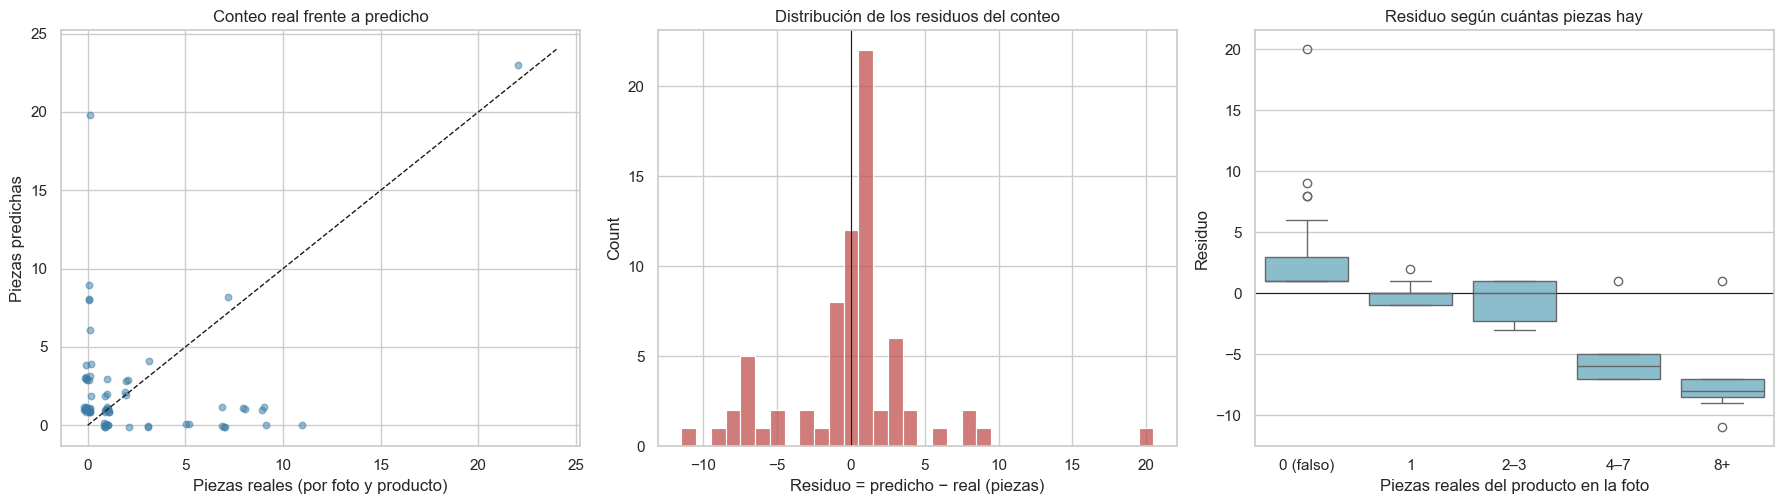

Pares (foto, producto): 72 | error absoluto medio 2.86 piezas | sesgo medio +0.00 | exactos 16.7% | a ±1 pieza 58.3%
Productos que el modelo inventa (real = 0, predicho > 0): 29 pares, 94 piezas | productos que omite (predicho = 0): 18 pares, 67 piezas
Total de piezas por foto: real = predicho en todas (cada caja recibe una etiqueta); el error es de reparto entre productos, no del total.


In [ ]:
d = pd.DataFrame({"foto": gte, "real": yte, "pred": pred_f}); rows_ = []
for foto, g in d.groupby("foto"):
    a, b = Counter(g.real), Counter(g.pred)
    rows_ += [{"foto": foto, "producto": c, "real": a[c], "predicho": b[c]} for c in set(a) | set(b)]
cnt = pd.DataFrame(rows_); cnt["residuo"] = cnt.predicho - cnt.real        # residuo > 0: el modelo cuenta de más; < 0: de menos
rng = np.random.default_rng(SEED); jit = lambda n: rng.uniform(-0.18, 0.18, n)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
axes[0].scatter(cnt.real + jit(len(cnt)), cnt.predicho + jit(len(cnt)), s=22, alpha=0.5, color="#3a7ca5"); mx = max(cnt.real.max(), cnt.predicho.max()) + 1
axes[0].plot([0, mx], [0, mx], "k--", lw=1); axes[0].set_xlabel("Piezas reales (por foto y producto)"); axes[0].set_ylabel("Piezas predichas"); axes[0].set_title("Conteo real frente a predicho")
sns.histplot(cnt.residuo, discrete=True, color="#c0504d", ax=axes[1]); axes[1].axvline(0, color="k", lw=0.8); axes[1].set_xlabel("Residuo = predicho − real (piezas)"); axes[1].set_title("Distribución de los residuos del conteo")
bins = pd.cut(cnt.real, [-1, 0, 1, 3, 7, 100], labels=["0 (falso)", "1", "2–3", "4–7", "8+"])
sns.boxplot(x=bins, y=cnt.residuo, ax=axes[2], color="#81c3d7"); axes[2].axhline(0, color="k", lw=0.8); axes[2].set_xlabel("Piezas reales del producto en la foto"); axes[2].set_ylabel("Residuo"); axes[2].set_title("Residuo según cuántas piezas hay")
fig.tight_layout(); plt.show()
print(f"Pares (foto, producto): {len(cnt)} | error absoluto medio {cnt.residuo.abs().mean():.2f} piezas | sesgo medio {cnt.residuo.mean():+.2f} | exactos {(cnt.residuo == 0).mean():.1%} | a ±1 pieza {(cnt.residuo.abs() <= 1).mean():.1%}")
print(f"Productos que el modelo inventa (real = 0, predicho > 0): {(cnt.real == 0).sum()} pares, {int(cnt.loc[cnt.real == 0, 'predicho'].sum())} piezas | productos que omite (predicho = 0): {(cnt.predicho == 0).sum()} pares, {int(cnt.loc[cnt.predicho == 0, 'real'].sum())} piezas")
print("Total de piezas por foto: real = predicho en todas (cada caja recibe una etiqueta); el error es de reparto entre productos, no del total.")

**Interpretación.** Cada punto es un par (foto, producto): cuántas piezas hay realmente frente a cuántas cuenta el modelo (si el modelo asigna una etiqueta a cada caja, el conteo de un producto es el número de cajas que le asigna).

- **Error medio de 2.86 piezas por par; solo el 16.7 % de los conteos es exacto** y el 58.3 % está a ±1 pieza. El sesgo medio es 0 porque el total de cajas por foto no cambia: **el error es un mal reparto entre productos, no un error de total**.
- **Subconteo creciente en los productos con muchas piezas.** El residuo (predicho − real) baja a ≈ −6 para productos con 4–7 piezas y a ≈ −8 con 8 o más: justamente los productos con más existencias, los que más importan en un inventario, son los que el modelo reparte entre otras etiquetas (el colapso de Bravecto sobre *1M Triple* y la absorción de varios viales por *Nobivac RL*, §9.1). Un producto de 22 piezas (*Nobivac DH2PPI*, bien diferenciado) se cuenta casi exacto (23), el único punto sobre la diagonal en la parte alta.
- **Productos inventados.** En 29 pares el modelo cuenta piezas de un producto que no está en la foto (94 piezas en total) y en 18 pares omite uno que sí está (67 piezas). El residuo extremo (+20) es *Nobivac RL*, que no está en esa foto y absorbió 20 cajas: las 11 de *Nobivac Puppy* y 9 de *Nobivac Intra-Trac*, viales de la misma línea que el modelo no separa; el mismo mecanismo hace que *Bravecto 1M Triple* se cuente de más (+8 a +9 en dos fotos) donde hay otras dosis de Bravecto.
- **Implicación:** el error de conteo no se arregla con un umbral ni con otro ensamble; hace falta distinguir mejor las presentaciones (texto del empaque, más ejemplos de las líneas subrepresentadas) o un conteo por línea/marca, donde el modelo sí es confiable.

### 9.6 Confianza del modelo y revisión humana

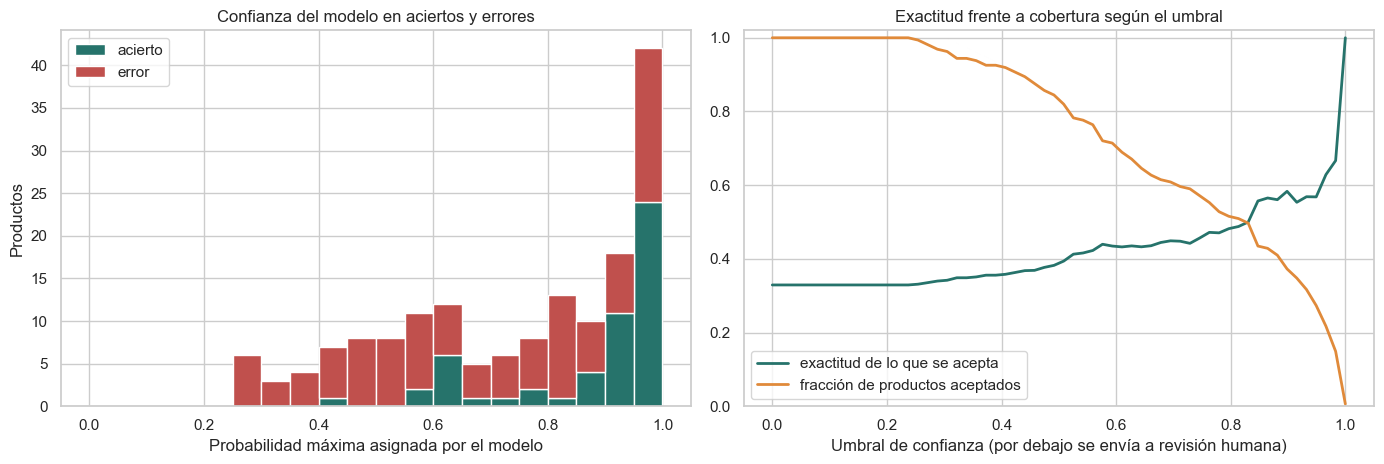

Umbral 0.57 (acepta el 75%): exactitud de los aceptados 42.1% | exactitud de los enviados a revisión 5.0%
Umbral 0.83 (acepta el 50%): exactitud de los aceptados 49.4% | exactitud de los enviados a revisión 16.2%
Umbral 0.95 (acepta el 25%): exactitud de los aceptados 56.1% | exactitud de los enviados a revisión 25.0%
Confianza media: aciertos 0.88 | errores 0.68


In [ ]:
thr = np.linspace(0, conf.max() - 1e-9, 60)
cover = [(conf >= t).mean() for t in thr]; acc_thr = [ok[conf >= t].mean() if (conf >= t).any() else np.nan for t in thr]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].hist([conf[ok], conf[~ok]], bins=np.linspace(0, 1, 21), stacked=True, color=["#26736b", "#c0504d"], label=["acierto", "error"]); axes[0].set_xlabel("Probabilidad máxima asignada por el modelo"); axes[0].set_ylabel("Productos"); axes[0].legend()
axes[0].set_title("Confianza del modelo en aciertos y errores")
axes[1].plot(thr, acc_thr, color="#26736b", lw=2, label="exactitud de lo que se acepta"); axes[1].plot(thr, cover, color="#e08a3a", lw=2, label="fracción de productos aceptados")
axes[1].set_xlabel("Umbral de confianza (por debajo se envía a revisión humana)"); axes[1].set_ylim(0, 1.02); axes[1].legend(); axes[1].set_title("Exactitud frente a cobertura según el umbral")
fig.tight_layout(); plt.show()
for q in (0.25, 0.5, 0.75):
    t = np.quantile(conf, q); print(f"Umbral {t:.2f} (acepta el {(conf >= t).mean():.0%}): exactitud de los aceptados {ok[conf >= t].mean():.1%} | exactitud de los enviados a revisión {ok[conf < t].mean():.1%}")
print(f"Confianza media: aciertos {conf[ok].mean():.2f} | errores {conf[~ok].mean():.2f}")

**Interpretación.**

- **La confianza ordena, pero el modelo es sobreconfiado.** La probabilidad máxima promedio es de 0.88 en los aciertos y de 0.68 en los errores, así que sirve para priorizar la revisión: el 25 % de productos con menor confianza (< 0.57) se acierta **solo el 5 %** de las veces, por lo que enviarlo a un operador es casi siempre correcto.
- **Pero la confianza alta no garantiza el acierto.** De los 42 productos con probabilidad ≥ 0.95, **18 (43 %) son errores**; aceptar automáticamente el 25 % más confiado da una exactitud de solo 56 %, y el 50 % más confiado, 49 %. La regresión logística con poca regularización (C ≈ 16) produce probabilidades extremas aunque la información sea ambigua entre presentaciones casi idénticas.
- **Implicación:** las probabilidades sirven para **marcar lo dudoso** (por debajo de ≈ 0.6 casi todo es error), no para certificar lo seguro. Antes de usarlas como umbral de aceptación automática conviene **calibrarlas** (calibración isotónica o por temperatura) con datos de validación y revisar también las predicciones de las líneas con pocos ejemplos.

## 10. Guardado del modelo final y de las tablas

Se guardan en carpetas locales del proyecto (no se publican en el repositorio): el modelo final, la tabla comparativa completa y las predicciones de prueba.

In [ ]:
out_dir = EXPORT_DIR.parent.parent
(out_dir / "03_modelos").mkdir(exist_ok=True); (out_dir / "04_resultados").mkdir(exist_ok=True)
joblib.dump({"modelo": final_est, "algoritmo": FINAL_NAME, "representacion": VIEW, "clases": list(final_est.classes_)}, out_dir / "03_modelos" / "avance5_modelo_final.joblib")
res.assign(params=res.params.astype(str)).to_csv(out_dir / "04_resultados" / "avance5_comparativa_modelos.csv")
pd.DataFrame({"foto": gte, "real": yte, "predicho": pred_f, "confianza": conf}).to_csv(out_dir / "04_resultados" / "avance5_predicciones_prueba.csv", index=False)
print("Guardados:", "03_modelos/avance5_modelo_final.joblib · 04_resultados/avance5_comparativa_modelos.csv · 04_resultados/avance5_predicciones_prueba.csv")

Guardados: 03_modelos/avance5_modelo_final.joblib · 04_resultados/avance5_comparativa_modelos.csv · 04_resultados/avance5_predicciones_prueba.csv


## 11. Resumen y conclusiones

La celda siguiente imprime las cifras calculadas en esta ejecución; el texto posterior las interpreta.

In [ ]:
ens = res[res.familia.str.startswith("Ensamble")]; ind = res[res.familia == "Individual (Avance 4)"]
print("RESUMEN — MODELO FINAL")
print(f"- {len(res)} modelos comparados con el mismo protocolo (validación cruzada de {cv.n_splits} pliegues agrupada por foto): baseline del Avance 3, {len(ind)} individuales del Avance 4 y {len(ens)} ensambles "
      f"({(ens.familia == FAM_HOMO).sum()} homogéneos, {(ens.familia == FAM_HETERO).sum()} heterogéneos).")
print(f"- Mejor individual: {BEST_IND} (macro-F1 CV {res.loc[BEST_IND, 'macroF1_CV']:.3f} ± {res.loc[BEST_IND, 'desv_CV']:.3f}; prueba {res.loc[BEST_IND, 'macroF1_test']:.3f}).")
for fam in (FAM_HOMO, FAM_HETERO):
    e = ens[ens.familia == fam]; b = e.macroF1_CV.idxmax()
    print(f"- Mejor {fam.lower()}: {b} (CV {e.loc[b, 'macroF1_CV']:.3f} ± {e.loc[b, 'desv_CV']:.3f}; Δ frente al mejor individual {e.loc[b, 'dif_vs_mejor_ind']:+.3f}; gana en {e.loc[b, 'pliegues_ganados']} pliegues; prueba {e.loc[b, 'macroF1_test']:.3f}).")
print("- Macro-F1 CV de los ensambles: " + "; ".join(f"{n.split(' (')[0]} {r.macroF1_CV:.3f}" for n, r in ens.iterrows()) + ".")
print(f"- Ensambles con ventaja consistente (≥ 4/5 pliegues) sobre el mejor individual: {int(((wins >= 4) & res.familia.str.startswith('Ensamble')).sum())}.")
print(f"- Entrenamiento (s, con todo el entrenamiento): " + "; ".join(f"{n.split(' (')[0]} {r.t_entren_s:.1f}" for n, r in res.iterrows() if n in ens.index.tolist() + [BEST_IND]) + ".")
print(f"- Modelo final: {FINAL_NAME}. Prueba (10 fotos): macro-F1 {fr.macroF1_test:.3f} {fr.IC95_macroF1_test}, top-3 {fr.top3_test:.3f}, línea {fr.acc_línea_test:.3f}, marca {fr.acc_marca_test:.3f}, "
      f"conteos exactos {fr.conteos_exactos:.1%}, error de conteo {fr.error_conteo:.2f} piezas (Avance 3: {res.loc['Baseline Avance 3 (LR, C=0.3, A)', 'error_conteo']:.2f}).")
print(f"- Meta propuesta en el Avance 3 (macro-F1 ≥ 0.80 y ≥ 90 % de conteos exactos): macro-F1 CV {fr.macroF1_CV:.3f}; conteos exactos {fr.conteos_exactos:.1%} -> sigue lejos.")

RESUMEN — MODELO FINAL
- 12 modelos comparados con el mismo protocolo (validación cruzada de 5 pliegues agrupada por foto): baseline del Avance 3, 4 individuales del Avance 4 y 7 ensambles (4 homogéneos, 3 heterogéneos).
- Mejor individual: Regresión logística (Av. 4) (macro-F1 CV 0.544 ± 0.128; prueba 0.253).
- Mejor ensamble homogéneo: Bagging de regresión logística (CV 0.491 ± 0.121; Δ frente al mejor individual -0.053; gana en 0/5 pliegues; prueba 0.230).
- Mejor ensamble heterogéneo: Votación suave (LR + LDA + MLP) (CV 0.518 ± 0.116; Δ frente al mejor individual -0.026; gana en 1/5 pliegues; prueba 0.272).
- Macro-F1 CV de los ensambles: Votación suave 0.518; Apilamiento 0.516; Bagging de regresión logística 0.491; Mezcla 0.478; Árboles extremadamente aleatorios 0.457; Bosque aleatorio 0.413; Gradient boosting 0.299.
- Ensambles con ventaja consistente (≥ 4/5 pliegues) sobre el mejor individual: 0.
- Entrenamiento (s, con todo el entrenamiento): Regresión logística 0.2; Votación s

### 11.1 Respuestas a lo que pide el avance

**Ensambles construidos (60 pts).** Se construyeron **7 ensambles** con las dos estrategias: **4 homogéneos** (bosque aleatorio, árboles extremadamente aleatorios, *bagging* de regresión logística y *gradient boosting* de histogramas) y **3 heterogéneos** (votación suave, apilamiento y mezcla). Los modelos base del apilamiento y la mezcla son los **cuatro mejores individuales del Avance 4** (regresión logística y LDA ajustados, SVM lineal y MLP). Se optimizaron hiperparámetros con búsqueda aleatoria (RF, ET, *bagging*, *boosting*), rejilla (votación, mezcla) y selección interna del C del metamodelo (apilamiento), siempre con validación cruzada de 5 pliegues agrupada por foto. El apilamiento y la mezcla se implementaron con particiones internas **por foto** y con un metamodelo de **pesos compartidos entre clases** (§6.4 muestra por qué).

**Comparativa y selección (20 pts).** La tabla de §7 ordena los 12 modelos (baseline del Avance 3, 4 individuales y 7 ensambles) por macro-F1 de validación cruzada e incluye *balanced accuracy*, top-3, exactitud por línea, desviación entre pliegues, tiempo de entrenamiento por pliegue y final, ventaja pareada sobre el mejor individual y, como confirmación, las métricas de prueba, el error de conteo, la latencia de inferencia y el tamaño.

| Posición | Modelo | macro-F1 CV | Δ vs mejor individual | prueba |
|---|---|---|---|---|
| 1 | Regresión logística (Av. 4) | 0.544 ± 0.128 | — | 0.253 |
| 2 | Votación suave (LR + LDA + MLP) | 0.518 ± 0.116 | −0.026 | 0.272 |
| 4 | Apilamiento | 0.516 ± 0.125 | −0.028 | 0.252 |
| 5 | *Bagging* de regresión logística | 0.491 ± 0.121 | −0.053 | 0.230 |
| 7 | Mezcla | 0.478 ± 0.095 | −0.066 | 0.248 |
| 9 | Árboles extremadamente aleatorios | 0.457 ± 0.124 | −0.087 | 0.193 |
| 10 | Bosque aleatorio | 0.413 ± 0.123 | −0.131 | 0.168 |
| 12 | *Gradient boosting* | 0.299 ± 0.174 | −0.245 | 0.121 |

(Los puestos 3, 6, 8 y 11 corresponden a LDA, SVM lineal, MLP y al baseline del Avance 3.)

**¿Mejoran los ensambles al mejor individual?** **No.** Ninguno gana en 4 o más de los 5 pliegues pareados y todos tienen menor macro-F1 medio. Tres hallazgos lo explican: (1) los errores son **compartidos**: en la prueba no acierta ningún modelo individual en el 61.5 % de los productos y solo en el 5.6 % exactamente uno acierta (§7.1); (2) el límite es la **información** de la representación y la escasez de ejemplos por clase, no la varianza del modelo: combinar representaciones distintas tampoco ayuda (§7.2); (3) con ≈ 12 productos por clase, un metamodelo flexible se sobreajusta (§6.4) y uno parsimonioso aprende a confiar casi solo en la regresión logística.

**Modelo final.** **Regresión logística sobre E** (la del Avance 4). Es la de mayor macro-F1, la más simple, interpretable, ligera y rápida, y entrega probabilidades; ver §8.

**Gráficos (20 pts).** Seis gráficos del modelo final con su interpretación (§9): matriz de confusión y F1 por producto, curva ROC, curva de precisión-recall, importancia de características, análisis de residuos del conteo y confianza frente a cobertura.

### 11.2 Qué dicen los gráficos del modelo final

El modelo identifica bien la **marca** (94 % en prueba) y bien los productos bien diferenciados (*Nobivac DH2PPI*, F1 ≈ 0.92), ordena razonablemente los puntajes (AUC macro 0.88), pero **colapsa casi todo Bravecto sobre *1M Triple*** (§9.1) y por eso el conteo de los productos con más piezas queda subestimado (§9.5). Se apoya casi solo en el *embedding* de ConvNeXt (§9.4) y su confianza es útil para priorizar revisión (el 25 % menos confiado se acierta el 5 % de las veces) pero no para certificar aciertos (43 % de error entre las predicciones con probabilidad ≥ 0.95, §9.6).

### 11.3 Limitaciones

- **La prueba tiene solo 10 fotos (161 productos) y su composición difiere de la del entrenamiento.** *Bravecto por peso* tiene 2 productos en entrenamiento y 30 en prueba; *Bravecto 1M*, 20 y 27; y hay 3 clases (14 productos) que el entrenamiento nunca vio. Por eso el macro-F1 de prueba (0.12–0.27) es mucho menor que el de validación cruzada (0.30–0.54) y debe leerse como un rango, no como un valor puntual; los intervalos de incertidumbre se traslapan para casi todos los modelos.
- **Nueve clases tienen menos de cinco ejemplos y una solo uno**; su desempeño no es confiable.
- Los modelos comparados comparten la **misma representación** (ConvNeXt-Tiny congelada y características a mano): la diversidad entre sus miembros es limitada por construcción, y esa es la causa probable de que los ensambles no aporten. No se probó afinar la CNN.
- Las representaciones **no leen el texto** del empaque (dosis, número de tabletas), que es lo que distingue a las presentaciones más confundidas.
- Los hiperparámetros de los ensambles se buscaron con presupuestos acotados (12–30 configuraciones); una búsqueda más amplia podría mover un poco las cifras, aunque la distancia al mejor individual (0.03 a 0.25) es grande frente a lo que suelen aportar esas búsquedas (≈ 0.01 en el Avance 4).
- La meta propuesta en el Avance 3 (macro-F1 ≥ 0.80 y ≥ 90 % de conteos exactos) sigue lejos: 0.544 en validación cruzada y 16.7 % de conteos exactos en la prueba.

### 11.4 Siguientes pasos

1. **Más ejemplos y partición estratificada por línea** para *Bravecto por peso* y *Bravecto 1M* (la partición actual deja casi sin ejemplos en entrenamiento a las líneas que más pesan en la prueba).
2. **Leer el texto del empaque** (dosis, número de tabletas) y combinarlo con el modelo visual.
3. **Afinar la CNN de extremo a extremo** (*fine-tuning* con aumento de datos, en GPU) y volver a probar un ensamble con miembros realmente distintos (CNN afinada + modelo lineal + lector de texto): ahí el apilamiento sí podría aportar.
4. **Clasificación jerárquica** marca → línea → presentación, aprovechando que la marca ya se identifica casi siempre.
5. **Calibrar las probabilidades** y fijar con el cliente un umbral de revisión humana (§9.6).
6. **Detector de cajas + este clasificador** y evaluación del conteo de extremo a extremo; política de conteo de pilas acordada con el cliente.

## Referencias

- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly Media. [O'Reilly](https://learning.oreilly.com/library/view/hands-on-machine-learning/9781098125967/). Cap. 7 (*Ensemble Learning and Random Forests*).
- VanderPlas, J. (2022). *Python Data Science Handbook* (2.ª ed.). O'Reilly Media. Cap. 39, *Thinking About Model Validation*.
- Singh, A. (2023, 14 de julio). *Comprehensive guide to ensemble learning (with Python codes)*. Analytics Vidhya. https://www.analyticsvidhya.com/blog/2018/06/comprehensive-guide-for-ensemble-models/
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32.
- Geurts, P., Ernst, D., & Wehenkel, L. (2006). Extremely randomized trees. *Machine Learning, 63*(1), 3–42.
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232.
- Wolpert, D. H. (1992). Stacked generalization. *Neural Networks, 5*(2), 241–259.
- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305.
- Scikit-learn. [Ensemble methods](https://scikit-learn.org/stable/modules/ensemble.html), [`StratifiedGroupKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html), [`RandomizedSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html).

# Declaración de uso de IA y contribución del equipo

### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
|---|---|---|---|
| Anthropic. (2026). Claude Code (Claude Sonnet 5.5) [Modelo de lenguaje grande]. https://claude.com/claude-code | Escribir y depurar el código de los ensambles (bosque aleatorio, árboles extremadamente aleatorios, *bagging*, *gradient boosting*, votación, apilamiento y mezcla con particiones internas por foto), de la comparativa y de los gráficos del modelo final; ejecutar la libreta; redactar borradores de las explicaciones e interpretaciones | Código de las secciones 3 a 10 (el procesamiento de datos de la sección 2 se reutiliza del Avance 4) y borradores de los textos de las secciones 1 a 11 | Se ejecutó la libreta completa y en orden; se contrastó cada cifra citada en el texto con las salidas y las afirmaciones sobre los datos con las predicciones guardadas (se corrigió la atribución del residuo extremo del conteo); se detectaron y corrigieron tres defectos (metamodelo de apilamiento sobreajustado, PCA de 256 componentes inviable en los subconjuntos pequeños de la mezcla y tiempos de entrenamiento distorsionados por los hilos de BLAS); se verificó que la prueba no se usara para elegir modelos ni hiperparámetros |

### Contribución individual

| Integrante | Contribución al avance |
|---|---|
| Arnulfo Cavazos | Definió el alcance del avance a partir de las instrucciones y la rúbrica; dirigió y revisó el trabajo realizado con la herramienta de IA (diseño de la comparativa, ejecución de la libreta y revisión de resultados e interpretaciones). |
| Luis Felipe Neri Alvarado Fregoso | Recolpilar y mejorar el dataset con nuevas muestras y generacion de propios modelos de analisis |
| Luis Pablo Barragán Morales | Recolpilar y mejorar el dataset con nuevas muestras , y generacion de moldeos propios de analisis |

### Decisiones principales

<small>Las tres decisiones que más influyeron en el avance, con la alternativa que se descartó.</small>

<small><b>Decisión 1:</b> Apilamiento y mezcla con particiones internas por foto y un metamodelo de pesos compartidos entre clases</small>
- <small>Justificación: con ≈ 12 productos por clase, un metamodelo multinomial completo (6 724 parámetros) obtuvo un macro-F1 de 0.406–0.433 en los pliegues internos, frente a 0.542 del metamodelo de pesos compartidos (5 parámetros, un peso por modelo base); las particiones por foto evitan que el metamodelo se entrene con predicciones de modelos que vieron otras cajas de la misma foto.</small>
- <small>Alternativa descartada y motivo: el `StackingClassifier` estándar con metamodelo multinomial, porque no recibe las fotos (fuga de información), falla con las clases raras y en una primera prueba con este diseño el apilamiento obtuvo solo 0.31 de macro-F1 en validación cruzada.</small>

<small><b>Decisión 2:</b> Fijar, antes de mirar la prueba, que un ensamble solo desplaza al mejor individual si gana en al menos 4 de los 5 pliegues pareados</small>
- <small>Justificación: la desviación entre pliegues (≈ 0.12) es mayor que las diferencias entre modelos, de modo que nueve de los doce modelos quedan "empatados" por la regla de una desviación estándar; la comparación pareada en los mismos pliegues discrimina mejor y evita elegir por azar un modelo más costoso.</small>
- <small>Alternativa descartada y motivo: elegir el modelo con el mejor macro-F1 de prueba (la votación suave, 0.272), porque la prueba tiene solo 10 fotos, los intervalos de incertidumbre se traslapan casi por completo y usarla para decidir invalidaría su papel de confirmación independiente.</small>

<small><b>Decisión 3:</b> Conservar la regresión logística del Avance 4 como modelo final en lugar de un ensamble</small>
- <small>Justificación: ningún ensamble superó al mejor individual (el mejor, la votación suave, quedó 0.026 por debajo y ganó en 1 de 5 pliegues); los cuatro modelos individuales comparten sus errores (en la prueba no acierta ninguno en el 61.5 % de los productos), así que combinarlos no añade información, y la regresión logística es más simple, ligera e interpretable y entrega probabilidades por clase.</small>
- <small>Alternativa descartada y motivo: la votación suave (LR + LDA + MLP) o el apilamiento, porque cuestan varias veces más en tamaño y tiempo de inferencia y pierden interpretabilidad sin una ganancia demostrable.</small>